<div style="border-left: 10px solid #7c8a99; padding: 10px 18px; margin: 8px 0 4px; background: rgba(127,127,127,0.08); border-radius: 4px;">
<h1 style="font-size: 2.3em; margin: 0;">Liber Deprehensus</h1>
<h3 style="font-size: 1.35em; margin: 6px 0 0; font-weight: 500;">책장 사진 한 장 → 꽂힌 책의 <b>권수</b>와 <b>제목</b> (On-Device · LLM 미사용)</h3>
</div>

<div style="font-size: 1.15em; line-height: 1.7;">

- 제약: LLM·멀티모달 모델(GPT, Gemini, Claude 등) 사용 금지 — 모든 단계가 검출·분할·분류·OCR 전용 모델과 규칙으로 동작
- **Sub Model 1 · Book Count Extraction** (Block 1~3): 책을 찾고 걸러내고 나눠서 **권수** 확정
- **Sub Model 2 · Subtitle Detection** (Block 4~9): 책마다 글자를 찾고 읽고 바로잡아 **제목** 확정
- 각 Block 끝의 **✅ 확인** 셀에서 업로드한 사진이 그 Block을 통과하기 **전 | 후**를 나란히 본다
- `QUICK_RUN = True`(Cell 0): 학습을 최소로 줄여 흐름만 확인 · 정식 학습은 `False`로 (Colab 등)

</div>


<div style="border-left: 10px solid #7c8a99; padding: 10px 18px; margin: 8px 0 4px; background: rgba(127,127,127,0.08); border-radius: 4px;">
<h1 style="font-size: 2.3em; margin: 0;">아키텍처</h1>
<h3 style="font-size: 1.35em; margin: 6px 0 0; font-weight: 500;">두 개의 Sub Model이 이어진다 — 권수를 세는 쪽의 결과(책 크롭)가 제목을 읽는 쪽의 입력이 된다</h3>
</div>

<div style="font-size: 1.15em; line-height: 1.7;">

<img src="assets/architecture.png" alt="Liber Deprehensus 아키텍처" width="720">

**흐름**: 사진 → (Sub Model 1) 책 검출 → 가짜 책 필터 → 책 단위로 나누기 → **권수** → 책 크롭 ×N → (Sub Model 2) 업스케일 → 글자 위치 → 언어·방향 → 펴기 → 인식 → 교정 → **제목**

| 설계 블록 | 노트북 | 구현 상세 | 변경 이력 |
|---|---|---|---|
| Object Detection · YOLO11n-OBB | Block 1 | 공개 책등 데이터(Roboflow · Open Images)로 미세조정, 회전 상자 | — |
| Scaling Abstraction · SAM 2.1 | Block 2 | 마스크 모양으로 배경·벽·명함 제거 + 상자를 마스크에 맞게 다시 잡기 + 중복 합치기 | 필터에 상자 보정·중복 합치기 추가 |
| Book Image Chunking · ViT-Large | Block 3 | 4종 분류(`book`·`not_book`·`partial`·`multiple`) → 버림·합침·나눔 → **권수** | 흐름 확인은 DeiT-Small, 정식은 ViT-Large |
| Book Image Upscaling · FSRCNN (×N) | Block 4 | OpenCV `dnn_superres`, 책마다 배율 자동(작은 크롭만 x2~x4) | — |
| Detect Text Box · PP-OCRv5 det (DBNet) | Block 5 | `PP-OCRv5_mobile_det`, 입력을 줄이지 않게 설정 | — |
| Language Detection · PP-OCRv5 rec (SVTR) | Block 6 | `korean_PP-OCRv5_mobile_rec` 점수로 언어 + 읽는 방향(90°·180°·세로쓰기) 결정 | 방향 판별 추가 |
| ROI Alignment & Warp · Perspective Warp + CLAHE | Block 7 | 원근 변환 + 여백 + 방향 적용 + 대비 보정 (학습 없는 기하 처리) | PP-OCRv5 STN → 기하 처리 |
| Text Recognition · TrOCR | Block 8 | 한국어 `team-lucid/trocr-small-korean` · 영어 `microsoft/trocr-*-printed` | — |
| Text Normalization · Rule + Char 5-gram LM + Catalog Matching | Block 9 | 규칙 정리 → 단어 교정·어순(글자 5-gram) → 도서 목록 매칭 (모두 비신경망) | mBART-50 → 제외 (1차 테스트: 고친 제목 0건 · 지어낸 문장 6건) |

</div>


In [81]:
# Cell 0 · 환경 설정: 경로, 디바이스, 시드
import os

os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")  # MPS 미지원 연산은 CPU로 (torch import 전에 설정)

from pathlib import Path
import random
import sys

import numpy as np
import torch

ROOT = Path.cwd()
WEIGHTS = ROOT / "weights"
SAMPLES = ROOT / "samples"
OUTPUTS = ROOT / "outputs"
for d in (WEIGHTS, SAMPLES, OUTPUTS):
    d.mkdir(exist_ok=True)

if torch.cuda.is_available():
    DEVICE = "cuda"
elif torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"

SEED = 42

# 빠른 확인 모드: 학습을 최소로 줄여 파이프라인이 끝까지 도는지만 확인한다.
# 정식 학습(Colab Pro 등)에서는 False로 바꾼다.
QUICK_RUN = True

# 여러 셀이 함께 쓰는 경로·설정 (중간 셀을 건너뛰어도 뒤 셀이 돌도록 여기서 정의)
DATA = ROOT / "data"
RAW = DATA / "raw"                        # 데이터 원본 다운로드
SRC = DATA / "src"                        # 출처별 변환 결과: SRC/<출처>/{images,labels}
DS = DATA / "books_obb"                   # 통합 학습 데이터셋
DATA_YAML = DS / "data.yaml"
DET_WEIGHTS = WEIGHTS / "det_obb_best.pt"  # Block 1 검출기 (Cell 1-4 또는 Colab 학습 결과)
DET_IMGSZ = 640 if QUICK_RUN else 1024     # 검출기 입력 크기 (책등이 가늘어 정식 학습은 크게)
CHUNK_DS = DATA / "chunk_cls"             # Block 3 분류 학습 데이터 (책 조각 이미지)
CHUNK_DIR = WEIGHTS / "chunk_vit"         # Block 3 ViT 분류기
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print(f"PYTHON : {sys.executable}")
if "liber_deprehensus/liber/" not in sys.executable:
    print("⚠️  liber 가상환경 커널이 아닙니다 → 오른쪽 위 커널 선택에서 'Python (liber)'로 바꾸세요")
print(f"ROOT   : {ROOT}")
print(f"DEVICE : {DEVICE}")
print(f"torch  : {torch.__version__}")
print(f"QUICK  : {QUICK_RUN}")

PYTHON : /Users/minseok/Downloads/shelf_ocr_test/liber_deprehensus/liber/bin/python
ROOT   : /Users/minseok/Downloads/shelf_ocr_test/liber_deprehensus
DEVICE : mps
torch  : 2.14.1
QUICK  : True


In [82]:
# Cell T · 테스트 사진 업로드 (모든 Block의 확인용 입력)
#   - 업로드한 사진은 samples/에 JPG로 저장되고, samples/의 사진 전체가 TEST_IMAGES가 된다
#   - 아이폰 HEIC는 JPG로 변환, EXIF 회전 정보는 픽셀에 반영
#   - 위젯 대신 samples/ 폴더에 사진을 직접 넣고 이 셀을 다시 실행해도 된다
import io

import ipywidgets as widgets
from IPython.display import display
from PIL import Image, ImageOps
from pillow_heif import register_heif_opener

register_heif_opener()
SAMPLE_EXTS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}


def list_test_images():
    return sorted(p for p in SAMPLES.iterdir() if p.suffix.lower() in SAMPLE_EXTS)


def save_upload(change):
    global TEST_IMAGES
    for f in change["new"]:
        img = ImageOps.exif_transpose(Image.open(io.BytesIO(bytes(f["content"])))).convert("RGB")
        out = SAMPLES / f"{Path(f['name']).stem}.jpg"
        img.save(out, quality=95)
        log.append_stdout(f"저장: {out.name} ({img.width}x{img.height})\n")
    TEST_IMAGES = list_test_images()
    log.append_stdout(f"TEST_IMAGES {len(TEST_IMAGES)}장\n")


uploader = widgets.FileUpload(accept="image/*,.heic,.heif", multiple=True, description="책장 사진")
log = widgets.Output()
uploader.observe(save_upload, names="value")
TEST_IMAGES = list_test_images()
display(uploader, log)
print(f"현재 TEST_IMAGES {len(TEST_IMAGES)}장 (samples/)")

FileUpload(value=(), accept='image/*,.heic,.heif', description='책장 사진', multiple=True)

Output()

현재 TEST_IMAGES 6장 (samples/)


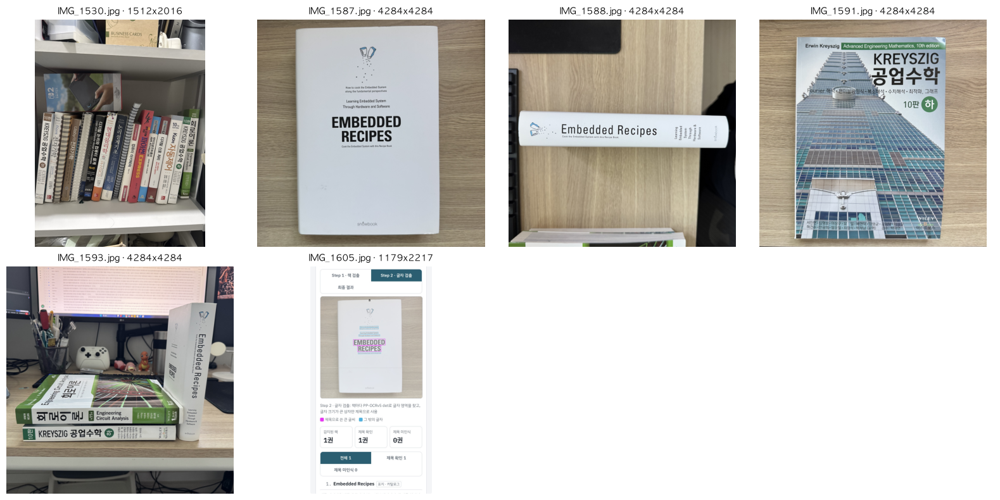

In [83]:
# Cell V · 단계별 확인 도구 + ✅ 업로드 사진 확인
#   - 각 Block 끝의 '✅ 확인' 셀이 이 함수들로 업로드 사진이 어떻게 처리됐는지 보여준다
#     규칙: 사진 1장 = 1행, [통과 전 | 통과 후 | (참고 그림)] 을 좌우로 나란히
#   - 사진 업로드(Cell T) 후 이 셀을 실행하면 업로드된 원본부터 보여준다
import cv2
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib import font_manager

# 그림 제목 한글 깨짐 방지: macOS AppleGothic, Colab/리눅스는 NanumGothic(apt install fonts-nanum)
_fonts = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams["font.family"] = next((f for f in ("AppleGothic", "NanumGothic") if f in _fonts), "DejaVu Sans")
plt.rcParams["axes.unicode_minus"] = False


def to_rgb(img_bgr):
    return cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)


def draw_dets(img_bgr, dets, color=(255, 0, 0), labels=None):
    """회전 상자를 그린 RGB 이미지. labels가 있으면 상자마다 글자 표시"""
    vis = to_rgb(img_bgr)
    t = max(2, vis.shape[1] // 400)
    for i, d in enumerate(dets):
        cv2.polylines(vis, [d["poly"].astype(np.int32)], True, color, t)
        if labels:
            x, y = d["poly"].min(axis=0).astype(int)
            text = str(labels[i]).replace("→", "->")  # OpenCV 기본 글꼴은 ASCII만 그림 (→·한글은 ??로 깨짐)
            cv2.putText(vis, text, (x, max(y - 4, 12)), cv2.FONT_HERSHEY_SIMPLEX, t * 0.4, color, t)
    return vis


def overlay_masks(img_bgr, masks, colors, alpha=0.45):
    """마스크마다 색을 반투명하게 덮은 RGB 이미지"""
    vis = to_rgb(img_bgr).astype(np.float32)
    for m, c in zip(masks, colors):
        vis[m] = vis[m] * (1 - alpha) + np.array(c, np.float32) * alpha
    return vis.astype(np.uint8)


def palette(n, seed=0):
    g = np.random.default_rng(seed)
    return [tuple(int(v) for v in g.integers(60, 256, 3)) for _ in range(n)]


def show_grid(items, cols=4, size=4):
    """items: [(제목, RGB 이미지), ...]를 격자로"""
    if not items:
        print("(보여줄 이미지 없음)")
        return
    rows_ = (len(items) + cols - 1) // cols
    fig, axes = plt.subplots(rows_, cols, figsize=(cols * size, rows_ * size), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, (title, im) in zip(axes.flat, items):
        ax.imshow(im)
        ax.set_title(title, fontsize=10)
    plt.tight_layout()
    plt.show()


def show_rows(rows, size=5):
    """rows: [(사진 이름, [(제목, RGB 이미지), ...]), ...] — 사진 1장 = 1행, 왼쪽부터 통과 전 → 통과 후 → 참고"""
    if not rows:
        print("(보여줄 이미지 없음)")
        return
    n_cols = max(len(panels) for _, panels in rows)
    fig, axes = plt.subplots(len(rows), n_cols, figsize=(n_cols * size, len(rows) * size), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for r, (row_title, panels) in enumerate(rows):
        for c, (title, im) in enumerate(panels):
            axes[r, c].imshow(im)
            axes[r, c].set_title(f"[{row_title}]\n{title}" if c == 0 else title, fontsize=10)
    plt.tight_layout()
    plt.show()


TEST_IMAGES = list_test_images()
if TEST_IMAGES:
    show_grid([(f"{p.name} · {im.shape[1]}x{im.shape[0]}", to_rgb(im))
               for p in TEST_IMAGES for im in [cv2.imread(str(p))]])
else:
    print("업로드된 사진이 없습니다 → Cell T에서 업로드하거나 samples/에 넣고 다시 실행 (없으면 val 사진으로 확인)")

<div style="border-left: 10px solid #e57373; padding: 10px 18px; margin: 8px 0 4px; background: rgba(127,127,127,0.08); border-radius: 4px;">
<h1 style="font-size: 2.3em; margin: 0;">Block 1 · Object Detection (YOLO11n-OBB)</h1>
<h3 style="font-size: 1.35em; margin: 6px 0 0; font-weight: 500;">책장 사진에서 책 한 권 한 권을 회전 상자로 찾는다 &nbsp;<small>[Sub Model 1 · Book Count]</small></h3>
</div>

<div style="font-size: 1.15em; line-height: 1.7;">

책장 사진에서 책 한 권 한 권을 **회전 상자(OBB)** 로 찾는다. 공개 데이터셋으로 새로 학습한다.

| 출처 | 라벨 | 라이선스 | 비고 |
|---|---|---|---|
| Roboflow Universe 책등 데이터 | 다각형/회전 상자 → 최소 외접 회전 사각형 | CC BY 4.0 | 기울어진 책등 학습의 주 데이터 |
| Open Images V7 `Book` | 수평 상자 → 회전각 0 사각형 | 주석 CC BY 4.0 · 이미지 CC BY 2.0 | 다양한 장면·배경 보강 |

실행 전: `export ROBOFLOW_API_KEY=...` (무료 계정 키) 후 노트북 커널 재시작.

</div>


In [ ]:
# Cell 1-1 · [Object Detection 데이터 ①] Roboflow 책등 데이터 → OBB 라벨
#   - 각 프로젝트 페이지에서 라이선스(CC BY 4.0)를 확인한 것만 목록에 남긴다
#   - 다각형 → 최소 외접 회전 사각형, 수평 상자 → 회전각 0 사각형
#   - 클래스는 모두 'book' 하나로 통합
import os
import shutil

import cv2
import pandas as pd
from dotenv import load_dotenv
from PIL import Image
from roboflow import Roboflow

IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# (workspace, project, version) — version=None이면 최신 버전
ROBOFLOW_SOURCES = [
    ("book-detection", "book-spine-detection-p2", None),
    ("minhaz", "book_spine_instance_segmentation-uqybb", None),
    ("emptybookslotdetect", "book-spine-seg", None),
    ("libvision", "book-spines-vh9b8", None),
]


def to_obb(values, w, h):
    """YOLO 라벨 한 줄(클래스 제외) → 정규화 4꼭짓점 [x1, y1, ..., x4, y4]. 형식이 틀리거나 너무 작으면 None."""
    if len(values) == 4:  # cx cy bw bh
        cx, cy, bw, bh = values
        pts = np.array([[cx - bw / 2, cy - bh / 2], [cx + bw / 2, cy - bh / 2],
                        [cx + bw / 2, cy + bh / 2], [cx - bw / 2, cy + bh / 2]])
    elif len(values) >= 6 and len(values) % 2 == 0:  # 다각형 (OBB 8값 포함)
        poly = (np.array(values).reshape(-1, 2) * [w, h]).astype(np.float32)
        pts = cv2.boxPoints(cv2.minAreaRect(poly)) / [w, h]
    else:
        return None
    pts = np.clip(pts, 0, 1)
    if cv2.contourArea(pts.astype(np.float32)) < 1e-5:
        return None
    return pts.reshape(-1).tolist()


def write_obb_label(path, obbs):
    path.write_text("\n".join("0 " + " ".join(f"{v:.6f}" for v in o) for o in obbs) + "\n")


load_dotenv(ROOT / ".env")  # ROBOFLOW_API_KEY=... 한 줄 (저장소에 올리지 않음)
assert os.getenv("ROBOFLOW_API_KEY"), f"{ROOT / '.env'}에 ROBOFLOW_API_KEY=키 를 넣으세요"
rf = Roboflow(api_key=os.environ["ROBOFLOW_API_KEY"])
summary = []
for ws, proj, ver in ROBOFLOW_SOURCES:
    name = f"rf_{proj}"
    try:
        project = rf.workspace(ws).project(proj)
        if ver is None:
            ver = max(int(str(v.version).split("/")[-1]) for v in project.versions())
        project.version(ver).download("yolov8", location=str(RAW / name), overwrite=False)
    except Exception as e:
        print(f"[skip] {ws}/{proj}: {e}")
        continue

    out_img, out_lbl = SRC / name / "images", SRC / name / "labels"
    out_img.mkdir(parents=True, exist_ok=True)
    out_lbl.mkdir(parents=True, exist_ok=True)
    n_img = n_box = 0
    for img_path in sorted((RAW / name).rglob("*")):
        if img_path.suffix.lower() not in IMG_EXTS or img_path.parent.name != "images":
            continue
        lbl_path = img_path.parent.parent / "labels" / f"{img_path.stem}.txt"
        if not lbl_path.exists():
            continue
        w, h = Image.open(img_path).size
        obbs = []
        for line in lbl_path.read_text().splitlines():
            vals = line.split()
            if len(vals) >= 5 and (obb := to_obb([float(v) for v in vals[1:]], w, h)):
                obbs.append(obb)
        if not obbs:
            continue
        stem = f"{img_path.parent.parent.name}_{img_path.stem}"  # Roboflow 분할 이름을 붙여 파일명 충돌 방지
        shutil.copy2(img_path, out_img / f"{stem}{img_path.suffix.lower()}")
        write_obb_label(out_lbl / f"{stem}.txt", obbs)
        n_img += 1
        n_box += len(obbs)
    summary.append({"source": name, "version": ver, "images": n_img, "boxes": n_box})

pd.DataFrame(summary)

In [ ]:
# Cell 1-2 · [Object Detection 데이터 ②] Open Images V7 'Book' → OBB 라벨 (회전각 0)
#   - 책 묶음(IsGroupOf)·그림 속 책(IsDepiction) 상자가 하나라도 있는 사진은 제외
#     (묶음 안의 책들은 개별 라벨이 없어 '책이 아님'으로 잘못 학습되기 때문)
#   - 책이 MIN_BOOKS권 이상 있는 사진만 사용 → 책장에 가까운 장면 위주
from concurrent.futures import ThreadPoolExecutor

import requests

OI_DIR = ROOT.parent / "datasets" / "openimages"  # 주석 CSV는 상위 프로젝트에 이미 받아 둠
BOOK_MID = "/m/0bt_c3"
MIN_BOOKS = 4
OI_MAX = 1500
OI_LONG_SIDE = 1280  # 저장 시 긴 변 축소 (라벨은 정규화 좌표라 그대로)
OI_CSVS = {
    "train": "oidv6-train-annotations-bbox.csv",
    "validation": "validation-annotations-bbox.csv",
    "test": "test-annotations-bbox.csv",
}
COLS = ["ImageID", "LabelName", "XMin", "XMax", "YMin", "YMax", "IsGroupOf", "IsDepiction"]

frames = []
for split, fname in OI_CSVS.items():
    for chunk in pd.read_csv(OI_DIR / fname, usecols=COLS, chunksize=2_000_000):
        chunk = chunk[chunk.LabelName == BOOK_MID]
        if len(chunk):
            frames.append(chunk.assign(split=split))
books = pd.concat(frames, ignore_index=True)

per_img = books.groupby(["split", "ImageID"]).agg(
    n=("ImageID", "size"), group=("IsGroupOf", "max"), depiction=("IsDepiction", "max")
).reset_index()
keep = per_img[(per_img.group != 1) & (per_img.depiction != 1) & (per_img.n >= MIN_BOOKS)]
print(f"Book 상자 {len(books):,}개 / 사진 {len(per_img):,}장 → 조건 통과 {len(keep):,}장")
keep = keep.sample(n=min(OI_MAX, len(keep)), random_state=SEED)
boxes_by_id = books[books.ImageID.isin(keep.ImageID)].groupby("ImageID")

oi_img, oi_lbl = SRC / "openimages" / "images", SRC / "openimages" / "labels"
oi_img.mkdir(parents=True, exist_ok=True)
oi_lbl.mkdir(parents=True, exist_ok=True)


def fetch(row):
    out = oi_img / f"{row.ImageID}.jpg"
    if not out.exists():
        url = f"https://open-images-dataset.s3.amazonaws.com/{row.split}/{row.ImageID}.jpg"
        try:
            r = requests.get(url, timeout=30)
            r.raise_for_status()
        except requests.RequestException:
            return False
        img = cv2.imdecode(np.frombuffer(r.content, np.uint8), cv2.IMREAD_COLOR)
        if img is None:
            return False
        s = OI_LONG_SIDE / max(img.shape[:2])
        if s < 1:
            img = cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
        cv2.imwrite(str(out), img, [cv2.IMWRITE_JPEG_QUALITY, 92])
    b = boxes_by_id.get_group(row.ImageID)
    obbs = [[x0, y0, x1, y0, x1, y1, x0, y1]
            for x0, x1, y0, y1 in b[["XMin", "XMax", "YMin", "YMax"]].itertuples(index=False)]
    write_obb_label(oi_lbl / f"{row.ImageID}.txt", obbs)
    return True


with ThreadPoolExecutor(16) as ex:
    ok = list(ex.map(fetch, keep.itertuples(index=False)))
print(f"Open Images: {sum(ok):,}/{len(keep):,}장 저장 → {oi_img}")

In [ ]:
# Cell 1-3 · [Object Detection 데이터 ③] 출처 통합 · 중복 제거 · train/val 분할 · data.yaml
#   - 같은 사진이 여러 Roboflow 프로젝트에 복제된 경우가 많아 dHash로 중복 제거
#   - Roboflow 증강 사본('<원본>_jpg.rf.<해시>')은 원본 단위로 묶어 train/val을 나눔
#     (같은 사진의 회전·크롭 사본이 양쪽에 들어가면 val 점수가 부풀려짐)
#   - 묶음당 train은 MAX_PER_GROUP장, val은 1장만 사용 (증강은 학습 중 ultralytics가 다시 함)
#   - 출처마다 VAL_RATIO만큼 val로 떼어 출처별 성능을 따로 볼 수 있게 함
#   - Roboflow 원본 파일명은 255바이트를 넘기도 해서 '<출처>__<번호>'로 바꾸고, 원본 경로는 manifest.csv에 기록
import re
from collections import defaultdict

import yaml
import matplotlib.pyplot as plt

VAL_RATIO = 0.1
MAX_PER_GROUP = 3


def dhash(path, size=8):
    g = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if g is None:
        return None
    g = cv2.resize(g, (size + 1, size), interpolation=cv2.INTER_AREA)
    return np.packbits(g[:, 1:] > g[:, :-1]).tobytes()


def group_key(src_name, img):
    """같은 원본에서 나온 사진끼리 묶는 키. Roboflow '<분할>_<원본>_jpg.rf.<해시>' → '<원본>_jpg'"""
    if src_name.startswith("rf_"):
        return re.sub(r"^(train|valid|test)_", "", img.stem).split(".rf.")[0]
    return img.stem


if DS.exists():
    shutil.rmtree(DS)
for split in ("train", "val"):
    (DS / "images" / split).mkdir(parents=True)
    (DS / "labels" / split).mkdir(parents=True)

rng = random.Random(SEED)
seen, rows, n_dup, n_cap = set(), [], 0, 0
for src_dir in sorted(p for p in SRC.iterdir() if p.is_dir()):
    groups = defaultdict(list)
    for img in sorted((src_dir / "images").iterdir()):
        lbl = src_dir / "labels" / f"{img.stem}.txt"
        h = dhash(img) if lbl.exists() else None
        if h is None:
            continue
        if h in seen:
            n_dup += 1
            continue
        seen.add(h)
        groups[group_key(src_dir.name, img)].append((img, lbl))

    keys = sorted(groups)
    rng.shuffle(keys)
    n_val = max(1, int(len(keys) * VAL_RATIO)) if keys else 0
    for gi, key in enumerate(keys):
        split = "val" if gi < n_val else "train"
        members = groups[key]
        rng.shuffle(members)
        keep = members[:1 if split == "val" else MAX_PER_GROUP]
        n_cap += len(members) - len(keep)
        for img, lbl in keep:
            name = f"{src_dir.name}__{len(rows):06d}"
            dst = DS / "images" / split / f"{name}{img.suffix}"
            try:
                os.link(img, dst)  # 하드링크로 디스크 절약
            except OSError:
                shutil.copy2(img, dst)
            shutil.copy2(lbl, DS / "labels" / split / f"{name}.txt")
            rows.append({"name": name, "source": src_dir.name, "split": split, "group": key,
                         "boxes": len(lbl.read_text().splitlines()), "original": str(img.relative_to(DATA))})

DATA_YAML.write_text(yaml.safe_dump(
    {"path": str(DS), "train": "images/train", "val": "images/val", "names": {0: "book"}},
    allow_unicode=True, sort_keys=False,
))

manifest = pd.DataFrame(rows)
manifest.to_csv(DS / "manifest.csv", index=False)
stats = manifest.pivot_table(index="source", columns="split", values="boxes", aggfunc=["count", "sum"])
stats.columns = [f"{'images' if a == 'count' else 'boxes'}_{s}" for a, s in stats.columns]
print(f"중복 제거 {n_dup:,}장 · 사본 제한으로 제외 {n_cap:,}장 · 원본 묶음 {manifest.group.nunique():,}개 · data.yaml → {DATA_YAML}")
display(stats)

# 라벨 확인: train에서 무작위 6장
samples = rng.sample(sorted((DS / "images" / "train").iterdir()), 6)
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, img_path in zip(axes.flat, samples):
    img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    for line in (DS / "labels" / "train" / f"{img_path.stem}.txt").read_text().splitlines():
        pts = (np.array(line.split()[1:], dtype=float).reshape(4, 2) * [w, h]).astype(np.int32)
        cv2.polylines(img, [pts], True, (255, 0, 0), max(2, w // 400))
    ax.imshow(img)
    ax.set_title(img_path.stem.split("__")[0], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
# Cell 1-4 · [Object Detection 학습] YOLO11n-OBB 미세조정
#   - 시작 가중치: yolo11n-obb.pt (DOTA 항공사진 회전 물체 검출로 사전학습) → 'book' 1클래스로 미세조정
#   - 책등은 가늘고 길어서 정식 학습은 입력 크기를 640보다 키움(Cell 0의 DET_IMGSZ)
#   - QUICK_RUN: 학습 데이터 5%·1에폭·640으로 '돌아가는지만' 확인
#   - weights/det_obb_best.pt가 이미 있으면 학습을 건너뜀 → 다시 하려면 RETRAIN_DET = True
#   - 본학습은 colab_train_det.ipynb (Colab GPU: 1~3권 사진 보강 + 최대 150에폭) → 받은 det_obb_best.pt를 weights/에 넣으면 됨
#   - 결과: outputs/train/det_obb/ (학습 곡선·PR 곡선·검증 예측 그림)
from ultralytics import YOLO

EPOCHS = 1 if QUICK_RUN else 60
FRACTION = 0.05 if QUICK_RUN else 1.0  # 학습 데이터 사용 비율
BATCH = 8
PATIENCE = 15  # val mAP가 이만큼 에폭 동안 안 오르면 조기 종료
RETRAIN_DET = False

if DET_WEIGHTS.exists() and not RETRAIN_DET:
    print(f"기존 가중치 사용 → {DET_WEIGHTS} (다시 학습하려면 RETRAIN_DET = True)")
else:
    det_model = YOLO("yolo11n-obb.pt")  # 없으면 자동 다운로드
    det_model.train(
        data=str(DATA_YAML),
        epochs=EPOCHS,
        imgsz=DET_IMGSZ,
        batch=BATCH,
        fraction=FRACTION,
        device=DEVICE,
        patience=PATIENCE,
        seed=SEED,
        workers=4,
        project=str(OUTPUTS / "train"),
        name="det_obb",
        exist_ok=True,
        # 증강: 책장은 살짝 기울어 찍히는 경우가 많아 회전을 넣고, 상하 반전은 실제 장면에 없어 끔
        degrees=15.0,
        fliplr=0.5,
        flipud=0.0,
        mosaic=1.0,
        close_mosaic=10,
    )
    shutil.copy2(Path(det_model.trainer.save_dir) / "weights" / "best.pt", DET_WEIGHTS)
    print(f"학습 결과 → {det_model.trainer.save_dir}")
    print(f"최종 가중치 → {DET_WEIGHTS}")

In [84]:
# Cell 1-5 · [Object Detection 추론] 테스트 사진에서 책 회전 상자 검출
#   - 입력: TEST_IMAGES (Cell T). 비어 있으면 val 사진 4장으로 대신 확인
#   - 출력: PIPE[사진 이름] = {"image": BGR 원본, "dets": [{"idx": 번호, "poly": (4,2) 픽셀 꼭짓점, "conf": 신뢰도}, ...]}
#     → 다음 Block들이 이 PIPE에 결과를 이어 붙인다. 검출 번호(idx)는 끝까지 유지
from ultralytics import YOLO

DET_CONF = 0.25
assert DET_WEIGHTS.exists(), (
    f"검출기 가중치가 없습니다: {DET_WEIGHTS}\n"
    "→ Cell 1-4로 학습하거나, Colab에서 받은 best.pt를 이 경로에 넣으세요"
)
det_model = YOLO(str(DET_WEIGHTS))
# 가중치에 기록된 학습 입력 크기로 검출 (Colab 본학습 = 960, 맥 빠른 확인 = 640)
DET_IMGSZ = (getattr(det_model, "ckpt", None) or {}).get("train_args", {}).get("imgsz", DET_IMGSZ)
print(f"검출기 {DET_WEIGHTS.name} · 입력 {DET_IMGSZ}")


def detect_books(img_bgr):
    r = det_model.predict(img_bgr, imgsz=DET_IMGSZ, conf=DET_CONF, device=DEVICE, verbose=False)[0]
    if r.obb is None or len(r.obb) == 0:
        return []
    polys = r.obb.xyxyxyxy.cpu().numpy()
    confs = r.obb.conf.cpu().numpy()
    order = np.argsort([p[:, 0].mean() for p in polys])  # 왼쪽 → 오른쪽 순서로 번호
    return [{"idx": i, "poly": polys[k].astype(np.float32), "conf": float(confs[k])} for i, k in enumerate(order)]


inputs = TEST_IMAGES or sorted((DS / "images" / "val").iterdir())[:4]
PIPE = {}
for path in inputs:
    img = cv2.imread(str(path))
    PIPE[path.name] = {"image": img, "dets": detect_books(img)}
print(f"검출 완료 {len(PIPE)}장: " + ", ".join(f"{n} {len(r['dets'])}개" for n, r in PIPE.items()))

검출 완료 6장: IMG_1530.jpg 25개, IMG_1587.jpg 9개, IMG_1588.jpg 9개, IMG_1591.jpg 15개, IMG_1593.jpg 15개, IMG_1605.jpg 9개


In [ ]:
# Cell 1-6 · ✅ Block 1 확인: 업로드 사진 → 책 검출
#   [통과 전: 업로드 원본 | 통과 후: 검출 상자(번호)] 를 사진마다 좌우로, 아래에 신뢰도 요약 표
rows = []
for name, r in PIPE.items():
    dets = r["dets"]
    rows.append((name, [
        ("통과 전 · 업로드 원본", to_rgb(r["image"])),
        (f"통과 후 · 검출 {len(dets)}개 (번호)", draw_dets(r["image"], dets, labels=[d["idx"] for d in dets])),
    ]))
show_rows(rows, size=6)

display(pd.DataFrame([{
    "사진": n,
    "검출 수": len(r["dets"]),
    "평균 신뢰도": round(float(np.mean([d["conf"] for d in r["dets"]])), 3) if r["dets"] else None,
    "최저 신뢰도": round(min(d["conf"] for d in r["dets"]), 3) if r["dets"] else None,
} for n, r in PIPE.items()]))

<div style="border-left: 10px solid #e57373; padding: 10px 18px; margin: 8px 0 4px; background: rgba(127,127,127,0.08); border-radius: 4px;">
<h1 style="font-size: 2.3em; margin: 0;">Block 2 · Scaling Abstraction (SAM 2 필터)</h1>
<h3 style="font-size: 1.35em; margin: 6px 0 0; font-weight: 500;">SAM 2 마스크 모양으로 벽·명함·책상 같은 가짜 책을 걸러내고 상자를 다시 잡는다 &nbsp;<small>[Sub Model 1 · Book Count]</small></h3>
</div>

<div style="font-size: 1.15em; line-height: 1.7;">

YOLO가 책으로 잘못 잡은 **벽·책상·선반·명함** 등을 한 번 더 걸러내고, 남은 책의 상자를 **마스크에 맞게 다시 잡는다.**
검출 상자마다 SAM 2에 상자를 프롬프트로 넣어 물체 마스크를 얻고, **마스크 자체의 모양**으로 책인지 판단한다.

> 처음 버전은 "마스크가 검출 상자와 얼마나 겹치나(채움·넘침)"로 판단했는데, 검출 상자가 조금만 기울거나 넓어도
> 진짜 책이 제거되고 상자가 딱 맞는 명함 상자는 통과했다. → 검출 상자 품질에 기대지 않는 기준으로 변경.

| 판단 기준 | 책 | 걸러낼 것 |
|---|---|---|
| **적중** (검출 상자 중심이 마스크 안에 있는가) | 있음 | SAM이 엉뚱한 물체를 잡음 |
| **면적** (마스크 / 사진 전체) | 작음 | 책상·벽: 사진 대부분을 덮음 |
| **테두리** (사진 테두리 중 마스크가 닿은 비율) | 거의 안 닿음 | 책상·벽·선반: 사진 밖으로 이어짐 |
| **직사각형도** (마스크 볼록 껍질 면적 / 외접 회전 사각형 면적) | 직사각형에 가까움 (스프링 홈은 볼록 껍질이 메움) | 불규칙한 물체 |
| **종횡비** (마스크 사각형 긴 변 / 짧은 변) | 길쭉함 (책등 3↑, 표지 1.3~1.6) | 정사각형에 가까운 덩어리 |
| **중복** (마스크끼리 겹침 IoU) | 다른 책과 거의 안 겹침 | 같은 책을 여러 검출이 가리킴 → 신뢰도 높은 1개만 남김 |
| **상대 크기** (마스크 긴 변 / 남은 후보 중앙값) | 비슷한 크기 | 명함(너무 작음) · 선반(너무 긺) |

통과한 검출은 상자를 **마스크의 외접 회전 사각형으로 교체**한다 (원래 상자는 `poly_det`에 보관).
처리 순서: 모양 기준 → 중복 합치기 → 상대 크기 (배경·중복이 먼저 빠져야 중앙값이 책 크기를 대표함)

명함 상자처럼 **모양이 책과 같은 직사각형 물체**, 여러 권을 한 덩어리로 잡은 마스크는 이 단계에서 못 거른다 → Block 3 ViT가 맡는다.

</div>


In [85]:
# Cell 2-1 · [SAM 2 필터] 검출 상자 → 마스크 → 책이 아닌 것 제거 + 상자 다시 잡기
#   - 모델: SAM 2.1 (QUICK_RUN은 tiny, 아니면 base). ultralytics가 가중치 자동 다운로드
#   - 판단은 마스크 자체의 모양으로만 (검출 상자가 어긋나도 진짜 책이 제거되지 않게)
#   - 같은 책을 가리키는 검출(마스크 IoU 높음)은 신뢰도가 가장 높은 1개만 남김
#   - 기준값(SAM_RULES)은 Cell 2-2 표를 보며 조정한다
#   - 출력: PIPE[이름]["books"] = 남은 검출 (poly: 마스크 기준 회전 상자, poly_det: 원래 검출 상자, mask: bool 마스크)
#           PIPE[이름]["rejected"] = [(검출, 사유), ...]
from ultralytics import SAM

sam_model = SAM("sam2.1_t.pt" if QUICK_RUN else "sam2.1_b.pt")

SAM_RULES = {
    "max_area": 0.60,       # 마스크 / 사진 면적 상한 (책상·벽)
    "max_border": 0.25,     # 사진 테두리 중 마스크가 닿은 비율 상한 (사진 밖으로 이어지는 배경)
    "min_rect": 0.75,       # 직사각형도 하한 (볼록 껍질 기준)
    "min_aspect": 1.15,     # 종횡비 하한 (정사각형 덩어리)
    "dup_iou": 0.60,        # 마스크 IoU가 이 이상이면 같은 책으로 보고 합침
    "min_rel_size": 0.30,   # 긴 변 / 중앙값 하한 (명함 등)
    "max_rel_size": 2.50,   # 긴 변 / 중앙값 상한 (선반 등)
    "min_books_for_size": 3,  # 상대 크기 기준은 후보가 이 수 이상일 때만 적용
}


def mask_rect(mask):
    """마스크 가장 큰 덩어리의 외접 회전 사각형 → (4,2) 꼭짓점, 긴 변, 짧은 변. 빈 마스크면 None"""
    contours, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return None
    contour = max(contours, key=cv2.contourArea)
    rect = cv2.minAreaRect(contour)
    w, h = rect[1]
    hull_area = cv2.contourArea(cv2.convexHull(contour))
    return cv2.boxPoints(rect).astype(np.float32), max(w, h), min(w, h), hull_area


def mask_iou(a, b):
    inter = np.logical_and(a, b).sum()
    return float(inter / max(np.logical_or(a, b).sum(), 1))


def mask_features(mask, det_poly):
    h, w = mask.shape
    rect = mask_rect(mask)
    if rect is None:
        return None, {"hit": 0.0, "area": 0.0, "border": 0.0, "rect": 0.0, "aspect": 0.0, "long": 0.0}
    poly, long_, short, hull_area = rect
    cx, cy = det_poly.mean(axis=0).astype(int)
    border = np.concatenate([mask[0], mask[-1], mask[:, 0], mask[:, -1]])
    return poly, {
        "hit": float(mask[np.clip(cy, 0, h - 1), np.clip(cx, 0, w - 1)]),
        "area": float(mask.sum() / mask.size),
        "border": float(border.mean()),
        # 볼록 껍질 기준: 스프링 제본의 톱니 홈·글자 구멍 때문에 직사각형도가 깎이지 않게
        "rect": float(hull_area / max(long_ * short, 1.0)),
        "aspect": float(long_ / max(short, 1.0)),
        "long": float(long_),
    }


def sam_filter(img_bgr, dets, rules=SAM_RULES):
    if not dets:
        return [], []
    bboxes = [[*d["poly"].min(axis=0), *d["poly"].max(axis=0)] for d in dets]  # SAM은 수평 상자 프롬프트
    r = sam_model(img_bgr, bboxes=bboxes, device=DEVICE, verbose=False)[0]
    masks = r.masks.data.cpu().numpy().astype(bool)

    # 1차: 모양 기준
    cands, rejected = [], []
    for d, m in zip(dets, masks):
        poly, f = mask_features(m, d["poly"])
        d = {**d, "poly_det": d["poly"], "mask": m, "sam": f}
        reasons = []
        if poly is None:
            reasons.append("empty")
        else:
            if not f["hit"]:
                reasons.append("miss")
            if f["area"] > rules["max_area"]:
                reasons.append(f"area {f['area']:.2f}")
            if f["border"] > rules["max_border"]:
                reasons.append(f"border {f['border']:.2f}")
            if f["rect"] < rules["min_rect"]:
                reasons.append(f"rect {f['rect']:.2f}")
            if f["aspect"] < rules["min_aspect"]:
                reasons.append(f"aspect {f['aspect']:.2f}")
        if reasons:
            rejected.append((d, ", ".join(reasons)))
        else:
            cands.append({**d, "poly": poly})

    # 2차: 중복 합치기 — 신뢰도 높은 순으로 보며, 이미 남긴 마스크와 많이 겹치면 같은 책
    kept = []
    for d in sorted(cands, key=lambda d: -d["conf"]):
        same = next((k for k in kept if mask_iou(d["mask"], k["mask"]) >= rules["dup_iou"]), None)
        if same is None:
            kept.append({**d, "merged": []})
        else:
            same["merged"].append(d["idx"])
            rejected.append(({**d, "poly": d["poly_det"]}, f"dup→{same['idx']}"))
    cands = sorted(kept, key=lambda d: d["idx"])

    # 3차: 남은 후보끼리 크기 비교 (배경·중복이 먼저 빠져야 중앙값이 책 크기를 대표함)
    books = []
    med = np.median([d["sam"]["long"] for d in cands]) if cands else 0
    for d in cands:
        d["sam"]["rel_size"] = float(d["sam"]["long"] / med) if med else 1.0
        if len(cands) >= rules["min_books_for_size"] and not (
            rules["min_rel_size"] <= d["sam"]["rel_size"] <= rules["max_rel_size"]
        ):
            rejected.append(({**d, "poly": d["poly_det"]}, f"size {d['sam']['rel_size']:.2f}"))
        else:
            books.append(d)
    return books, rejected


for name, r in PIPE.items():
    r["books"], r["rejected"] = sam_filter(r["image"], r["dets"])
    print(f"{name}: 검출 {len(r['dets'])} → 책 {len(r['books'])} (제거 {len(r['rejected'])})")

IMG_1530.jpg: 검출 25 → 책 16 (제거 9)
IMG_1587.jpg: 검출 9 → 책 5 (제거 4)
IMG_1588.jpg: 검출 9 → 책 8 (제거 1)
IMG_1591.jpg: 검출 15 → 책 7 (제거 8)
IMG_1593.jpg: 검출 15 → 책 8 (제거 7)
IMG_1605.jpg: 검출 9 → 책 1 (제거 5)


In [ ]:
# Cell 2-2 · ✅ Block 2 확인: 검출 → SAM 2 마스크 → 필터 결과
#   [통과 전: YOLO 검출
#    | 통과 후: 초록=책(마스크 기준으로 다시 잡은 상자), 빨강=제거+사유, 회색=중복으로 합쳐진 검출
#    | 참고: 남은 책 마스크는 색색으로 채우고, 제거된 마스크는 빨간 윤곽선만 (중복은 생략)]
#   표: 검출마다 판단 기준 값 → SAM_RULES 조정에 사용


def mask_view(img_bgr, kept, removed):
    vis = overlay_masks(img_bgr, [d["mask"] for d in kept], palette(len(kept)))
    t = max(2, vis.shape[1] // 500)
    for d in removed:
        contours, _ = cv2.findContours(d["mask"].astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(vis, contours, -1, (255, 0, 0), t)
    return vis


rows, table = [], []
for name, r in PIPE.items():
    books = r["books"]
    dups = [(d, why) for d, why in r["rejected"] if why.startswith("dup")]
    rej = [(d, why) for d, why in r["rejected"] if not why.startswith("dup")]
    after = draw_dets(r["image"], [d for d, _ in dups], color=(150, 150, 150))
    after = draw_dets(cv2.cvtColor(after, cv2.COLOR_RGB2BGR), [d for d, _ in rej], color=(255, 0, 0),
                      labels=[f"{d['idx']}:{why}" for d, why in rej])
    after = draw_dets(cv2.cvtColor(after, cv2.COLOR_RGB2BGR), books, color=(0, 200, 0),
                      labels=[d["idx"] for d in books])
    rows.append((name, [
        (f"통과 전 · 검출 {len(r['dets'])}개", draw_dets(r["image"], r["dets"], labels=[d["idx"] for d in r["dets"]])),
        (f"통과 후 · 책 {len(books)}권 (제거 {len(rej)} · 중복 {len(dups)})", after),
        ("참고 · SAM 2 마스크 (색=책, 빨간 선=제거)", mask_view(r["image"], books, [d for d, _ in rej])),
    ]))
    reasons = {d["idx"]: why for d, why in r["rejected"]}
    for d in sorted(books + [d for d, _ in r["rejected"]], key=lambda d: d["idx"]):
        table.append({"사진": name, "번호": d["idx"], "conf": round(d["conf"], 2),
                      **{k: round(v, 2) for k, v in d["sam"].items()},
                      "합친 번호": d.get("merged") or "",
                      "결과": f"제거 ({reasons[d['idx']]})" if d["idx"] in reasons else "책"})

show_rows(rows, size=6)
pd.set_option("display.max_rows", 200)
display(pd.DataFrame(table))

<div style="border-left: 10px solid #e57373; padding: 10px 18px; margin: 8px 0 4px; background: rgba(127,127,127,0.08); border-radius: 4px;">
<h1 style="font-size: 2.3em; margin: 0;">Block 3 · Book Image Chunking (ViT)</h1>
<h3 style="font-size: 1.35em; margin: 6px 0 0; font-weight: 500;">ViT로 책 조각을 4종류로 분류해 최종 권수를 확정한다 &nbsp;<small>[Sub Model 1 · Book Count]</small></h3>
</div>

<div style="font-size: 1.15em; line-height: 1.7;">

Block 2를 통과한 조각을 책 1권 단위 이미지로 **바로 세워 잘라내고**, ViT로 4종류 중 하나로 분류해 **권수를 확정**한다.

| 분류 | 의미 | 처리 | 학습 데이터 (자동 생성) |
|---|---|---|---|
| `book` | 책 1권 | 1권으로 셈 | books_obb 정답 상자 그대로 |
| `not_book` | 명함 상자·판자·벽·모니터 등 | 버림 | 정답 상자와 안 겹치는 배경 + **책이 없는 Open Images 장면**(책상·모니터·건물 등) |
| `partial` | 책의 일부분 | 서로 겹치는 partial은 한 묶음 → 다른 책과 겹치면 버림, 아니면 확신이 높을 때만 1권 | 정답 상자의 25~60% 구간 |
| `multiple` | 여러 권이 한 덩어리 | 책 두께 기준으로 n권으로 나눔 | 이웃한 정답 상자 2~4개를 합친 상자 |

추가 안전장치
- **애매한 판정**(확신 < `min_conf`)은 나누거나 버리지 않고 Block 2 판단대로 1권 (`book?`로 표시)
- **최종 중복 제거**: 나눈 뒤 최종 상자끼리 많이 겹치면(A+B, B+C 덩어리를 각각 나눠 B가 두 번 생긴 경우 등) 1개만 남김

- 크롭은 긴 변이 세로가 되게 회전해 자른다 → 책등이 바로 서고, Block 4(업스케일)·Block 5(글자 인식)의 입력이 된다
- ViT 입력은 정사각형으로 **늘리지 않고 회색 여백을 붙여**(letterbox) 책의 가로세로 비율을 보존한다 (`book`과 `multiple`을 가르는 단서)
- 모델: `QUICK_RUN`은 DeiT-Small(ViT 구조, 22M)로 흐름 확인, 정식은 ViT-Large(304M) → 이후 양자화

</div>


In [ ]:
# Cell 3-1 · [Chunking 데이터] books_obb 정답 상자 → 4종류 책 조각 이미지 자동 생성
#   - 회전 크롭 함수(crop_rotated 등)는 Block 3~5가 같이 쓴다
#   - 출력: CHUNK_DS/{train,val}/{book,not_book,partial,multiple}/*.jpg
#   - 끝까지 만들어진 데이터(완료 표시 파일 .done)가 있으면 건너뜀 → 다시 만들려면 REBUILD_CHUNK = True
#     (중간에 오류로 멈춘 폴더는 완료 표시가 없어서 자동으로 다시 만든다)
#   - 주의: Open Images는 사진 속 책이 전부 라벨된 게 아니라 not_book에 책이 조금 섞일 수 있음
import shutil

CHUNK_CLASSES = ["book", "not_book", "partial", "multiple"]
CHUNK_MAX_IMAGES = {"train": 400, "val": 80} if QUICK_RUN else {"train": None, "val": None}  # None = 전부
PER_IMAGE = {"book": 3, "not_book": 3, "partial": 2, "multiple": 1}  # 사진 1장에서 뽑는 최대 수
CROP_MAX_SIDE = 320  # 저장 크기 (긴 변)
REBUILD_CHUNK = False


def rect_frame(poly):
    """회전 상자 → (p0, u, v): p0 꼭짓점, u = 긴 변 벡터, v = 짧은 변 벡터 (좌우 반전 없는 방향으로)"""
    box = cv2.boxPoints(cv2.minAreaRect(np.asarray(poly, np.float32)))
    for i in range(4):
        for step in (1, -1):
            p0, p1, p3 = box[i], box[(i + step) % 4], box[(i - step) % 4]
            u, v = p1 - p0, p3 - p0
            # 출력 좌표: v → 오른쪽(x), u → 아래(y). 이미지 좌표계에서 반전이 없으려면 cross(v, u) > 0
            if np.linalg.norm(u) >= np.linalg.norm(v) and v[0] * u[1] - v[1] * u[0] > 0:
                return p0, u, v
    p0, p1, p3 = box[0], box[1], box[3]
    return p0, p1 - p0, p3 - p0


def frame_poly(p0, u, v):
    return np.array([p0, p0 + u, p0 + u + v, p0 + v], np.float32)


def crop_rotated(img_bgr, poly):
    """회전 상자 영역을 긴 변이 세로가 되도록 바로 세워 잘라냄"""
    p0, u, v = rect_frame(poly)
    L, S = max(int(round(np.linalg.norm(u))), 1), max(int(round(np.linalg.norm(v))), 1)
    M = cv2.getAffineTransform(np.float32([p0, p0 + u, p0 + v]), np.float32([[0, 0], [0, L], [S, 0]]))
    return cv2.warpAffine(img_bgr, M, (S, L), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)


def split_poly(poly, n):
    """회전 상자를 짧은 변 방향으로 n등분 (여러 권 덩어리 → 낱권)"""
    p0, u, v = rect_frame(poly)
    return [frame_poly(p0 + v * k / n, u, v / n) for k in range(n)]


def limit_side(img, max_side):
    s = max_side / max(img.shape[:2])
    return cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA) if s < 1 else img


def read_obb(lbl_path, w, h):
    # float32로 고정: [w, h](정수 리스트)를 곱하면 float64가 되는데 OpenCV 도형 함수는 float32/int32만 받음
    return [(np.array(l.split()[1:9], np.float32).reshape(4, 2) * np.float32([w, h])).astype(np.float32)
            for l in lbl_path.read_text().splitlines() if len(l.split()) >= 9]


def make_chunk_samples(img, polys, rng_):
    """사진 1장 + 정답 상자 → {분류: [회전 상자, ...]}"""
    h, w = img.shape[:2]
    out = {k: [] for k in CHUNK_CLASSES}

    # book: 정답 상자 그대로
    for i in rng_.sample(range(len(polys)), min(PER_IMAGE["book"], len(polys))):
        out["book"].append(polys[i])

    # partial: 긴 변 방향 25~60% 구간
    for i in rng_.sample(range(len(polys)), min(PER_IMAGE["partial"], len(polys))):
        p0, u, v = rect_frame(polys[i])
        frac = rng_.uniform(0.25, 0.6)
        t0 = rng_.uniform(0, 1 - frac)
        out["partial"].append(frame_poly(p0 + u * t0, u * frac, v))

    # multiple: 이웃한 상자 2~4개를 감싸는 회전 상자 (실제로 붙어 있을 때만)
    order = sorted(range(len(polys)), key=lambda i: polys[i][:, 0].mean())
    for _ in range(5):
        if len(out["multiple"]) >= PER_IMAGE["multiple"] or len(order) < 2:
            break
        k = rng_.randint(2, min(4, len(order)))
        start = rng_.randint(0, len(order) - k)
        group = [polys[i] for i in order[start:start + k]]
        rect = cv2.minAreaRect(np.concatenate(group))
        if rect[1][0] * rect[1][1] <= 1.5 * sum(cv2.contourArea(g) for g in group):
            out["multiple"].append(cv2.boxPoints(rect))

    # not_book: 정답 상자와 비슷한 크기의 상자를 배경에 무작위로 (정답과 10% 미만으로 겹칠 때만)
    s = 0.25
    gt = np.zeros((max(int(h * s), 1), max(int(w * s), 1)), np.uint8)
    cv2.fillPoly(gt, [(p * s).astype(np.int32) for p in polys], 1)
    for _ in range(20):
        if len(out["not_book"]) >= PER_IMAGE["not_book"]:
            break
        (_, _), (bw, bh), ang = cv2.minAreaRect(polys[rng_.randrange(len(polys))])
        k = rng_.uniform(0.5, 1.5)
        box = cv2.boxPoints(((rng_.uniform(0, w), rng_.uniform(0, h)), (bw * k, bh * k), ang + rng_.uniform(-20, 20)))
        if box[:, 0].min() < 0 or box[:, 1].min() < 0 or box[:, 0].max() > w or box[:, 1].max() > h:
            continue
        m = np.zeros_like(gt)
        cv2.fillPoly(m, [(box * s).astype(np.int32)], 1)
        if m.sum() and (gt & m).sum() / m.sum() < 0.1:
            out["not_book"].append(box)
    return out


CHUNK_DONE = CHUNK_DS / ".done"
if CHUNK_DONE.exists() and not REBUILD_CHUNK:
    print(f"기존 데이터 사용 → {CHUNK_DS} (다시 만들려면 REBUILD_CHUNK = True)")
else:
    if CHUNK_DS.exists():
        shutil.rmtree(CHUNK_DS)
    rng_c = random.Random(SEED)
    for split in ("train", "val"):
        for k in CHUNK_CLASSES:
            (CHUNK_DS / split / k).mkdir(parents=True)
        imgs = sorted((DS / "images" / split).iterdir())
        rng_c.shuffle(imgs)
        imgs = imgs[:CHUNK_MAX_IMAGES[split]]
        for img_path in imgs:
            img = cv2.imread(str(img_path))
            if img is None:
                continue
            polys = read_obb(DS / "labels" / split / f"{img_path.stem}.txt", img.shape[1], img.shape[0])
            if not polys:
                continue
            for k, boxes in make_chunk_samples(img, polys, rng_c).items():
                for j, box in enumerate(boxes):
                    crop = crop_rotated(img, box)
                    if min(crop.shape[:2]) >= 8:
                        cv2.imwrite(str(CHUNK_DS / split / k / f"{img_path.stem}_{j}.jpg"),
                                    limit_side(crop, CROP_MAX_SIDE), [cv2.IMWRITE_JPEG_QUALITY, 90])
    CHUNK_DONE.touch()

display(pd.DataFrame({split: {k: len(list((CHUNK_DS / split / k).glob("*.jpg"))) for k in CHUNK_CLASSES}
                      for split in ("train", "val")}))

# 분류마다 4장씩 예시
ex = []
for k in CHUNK_CLASSES:
    for p in sorted((CHUNK_DS / "train" / k).glob("*.jpg"))[:4]:
        ex.append((k, to_rgb(cv2.imread(str(p)))))
show_grid(ex, cols=8, size=2.2)

In [ ]:
# Cell 3-1b · [Chunking 데이터 보강] 책이 없는 장면 → not_book
#   - 3-1의 not_book은 책장 사진의 배경뿐이라 책상·모니터·건물 외벽(표지 그림) 같은 장면이 없음
#   - Open Images val/test 주석에서 아래 물체가 있고 Book·Bookcase·Shelf가 없는 사진을 받아
#     책등·표지 비율의 회전 상자를 무작위로 잘라 not_book에 추가 (파일명 oi_neg_*)
#   - 끝까지 만들어지면 완료 표시(.done_neg) → 다음부터 건너뜀. 3-1을 다시 만들면 함께 지워짐
from concurrent.futures import ThreadPoolExecutor

import requests

OI_DIR = ROOT.parent / "datasets" / "openimages"
NEG_DIR = RAW / "oi_negatives"
NEG_CLASSES = ["Table", "Desk", "Kitchen & dining room table", "Countertop", "Computer monitor", "Laptop",
               "Television", "Box", "Cabinetry", "Chest of drawers", "Whiteboard", "Picture frame", "Poster",
               "Skyscraper", "Office building", "Building", "Window"]
EXCLUDE_CLASSES = ["Book", "Bookcase", "Shelf"]  # 책이 라벨 없이 찍혀 있을 수 있는 사진은 제외
NEG_IMAGES = 200 if QUICK_RUN else 2000
NEG_PER_IMAGE = 4
NEG_VAL_RATIO = 0.15
NEG_DONE = CHUNK_DS / ".done_neg"

if NEG_DONE.exists():
    print(f"기존 보강 데이터 사용 ({NEG_DONE})")
else:
    names = pd.read_csv(OI_DIR / "oidv7-class-descriptions-boxable.csv")
    mid = dict(zip(names.DisplayName, names.LabelName))
    ann = pd.concat([
        pd.read_csv(OI_DIR / f, usecols=["ImageID", "LabelName"]).assign(split=sp)
        for sp, f in [("validation", "validation-annotations-bbox.csv"), ("test", "test-annotations-bbox.csv")]
    ])
    bad = set(ann.ImageID[ann.LabelName.isin([mid[n] for n in EXCLUDE_CLASSES])])
    good = ann[ann.LabelName.isin([mid[n] for n in NEG_CLASSES]) & ~ann.ImageID.isin(bad)]
    picks = good.drop_duplicates("ImageID").sample(n=min(NEG_IMAGES, good.ImageID.nunique()), random_state=SEED)
    print(f"후보 사진 {good.ImageID.nunique():,}장 중 {len(picks)}장 사용")

    NEG_DIR.mkdir(parents=True, exist_ok=True)

    def fetch_neg(row):
        out = NEG_DIR / f"{row.ImageID}.jpg"
        if not out.exists():
            try:
                r = requests.get(f"https://open-images-dataset.s3.amazonaws.com/{row.split}/{row.ImageID}.jpg", timeout=30)
                r.raise_for_status()
            except requests.RequestException:
                return None
            img = cv2.imdecode(np.frombuffer(r.content, np.uint8), cv2.IMREAD_COLOR)
            if img is None:
                return None
            cv2.imwrite(str(out), limit_side(img, 1024), [cv2.IMWRITE_JPEG_QUALITY, 92])
        return out

    with ThreadPoolExecutor(16) as ex:
        paths = [p for p in ex.map(fetch_neg, picks.itertuples(index=False)) if p is not None]

    rng_n = random.Random(SEED)
    n_saved = {"train": 0, "val": 0}
    for i, path in enumerate(paths):
        img = cv2.imread(str(path))
        h, w = img.shape[:2]
        split = "val" if i < int(len(paths) * NEG_VAL_RATIO) else "train"
        for j in range(NEG_PER_IMAGE):
            aspect = rng_n.choice([rng_n.uniform(1.2, 1.7), rng_n.uniform(3, 12)])  # 표지 비율 / 책등 비율
            long_ = rng_n.uniform(0.15, 0.6) * max(h, w)
            short = long_ / aspect
            box = cv2.boxPoints(((rng_n.uniform(0, w), rng_n.uniform(0, h)), (short, long_), rng_n.uniform(-30, 30)))
            box[:, 0] = np.clip(box[:, 0], 0, w - 1)
            box[:, 1] = np.clip(box[:, 1], 0, h - 1)
            crop = crop_rotated(img, box)
            if min(crop.shape[:2]) >= 8:
                cv2.imwrite(str(CHUNK_DS / split / "not_book" / f"oi_neg_{path.stem}_{j}.jpg"),
                            limit_side(crop, CROP_MAX_SIDE), [cv2.IMWRITE_JPEG_QUALITY, 90])
                n_saved[split] += 1
    NEG_DONE.touch()
    print(f"not_book 보강: train {n_saved['train']}장 · val {n_saved['val']}장")

display(pd.DataFrame({split: {k: len(list((CHUNK_DS / split / k).glob("*.jpg"))) for k in CHUNK_CLASSES}
                      for split in ("train", "val")}))
show_grid([("not_book (보강)", to_rgb(cv2.imread(str(p))))
           for p in sorted((CHUNK_DS / "train" / "not_book").glob("oi_neg_*.jpg"))[:8]], cols=8, size=2.2)

In [ ]:
# Cell 3-2 · [Chunking 학습] ViT 4종류 분류기 미세조정
#   - QUICK_RUN: DeiT-Small(ViT 구조, 22M)·1에폭 → 흐름 확인용 / 본학습은 colab_train_vit.ipynb (ViT-Large·DeiT-Small, 조기 종료)
#   - 입력: 회색 여백(letterbox)으로 정사각형 → 224x224 (가로세로 비율 보존)
#   - 결과: CHUNK_DIR (save_pretrained). 같은 데이터로 학습한 분류기가 있으면 건너뜀
#     (학습 데이터 장수가 바뀌면 자동으로 다시 학습, 강제로 하려면 RETRAIN_CHUNK = True)
import json

from PIL import Image
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from transformers import AutoImageProcessor, AutoModelForImageClassification

VIT_NAME = "facebook/deit-small-patch16-224" if QUICK_RUN else "google/vit-large-patch16-224-in21k"
VIT_EPOCHS = 1 if QUICK_RUN else 5
VIT_BATCH = 32
VIT_LR = 1e-4 if QUICK_RUN else 3e-5
VIT_SIZE = 224
RETRAIN_CHUNK = False


class Letterbox:
    """비율을 유지해 줄이고 회색 여백으로 정사각형을 만든다 (PIL 이미지)"""

    def __init__(self, size, fill=(114, 114, 114)):
        self.size, self.fill = size, fill

    def __call__(self, im):
        s = self.size / max(im.size)
        im = im.resize((max(1, round(im.width * s)), max(1, round(im.height * s))), Image.BILINEAR)
        canvas = Image.new("RGB", (self.size, self.size), self.fill)
        canvas.paste(im, ((self.size - im.width) // 2, (self.size - im.height) // 2))
        return canvas


def vit_transform(processor, train=False):
    aug = [transforms.ColorJitter(0.3, 0.3, 0.3), transforms.RandomHorizontalFlip()] if train else []
    return transforms.Compose([Letterbox(VIT_SIZE), *aug, transforms.ToTensor(),
                               transforms.Normalize(processor.image_mean, processor.image_std)])


DATA_STAMP = json.dumps({sp: {k: len(list((CHUNK_DS / sp / k).glob("*.jpg"))) for k in CHUNK_CLASSES}
                         for sp in ("train", "val")}, sort_keys=True)
STAMP_FILE = CHUNK_DIR / "data_stamp.json"
same_data = STAMP_FILE.exists() and STAMP_FILE.read_text() == DATA_STAMP
if (CHUNK_DIR / "trained_on_colab.json").exists():   # Colab 본학습 결과(colab_train_vit.ipynb)는 맥 데이터와 달라도 그대로 사용
    same_data = True
    print("Colab 본학습 분류기:", json.loads((CHUNK_DIR / "trained_on_colab.json").read_text()))
if (CHUNK_DIR / "config.json").exists() and same_data and not RETRAIN_CHUNK:
    print(f"기존 분류기 사용 → {CHUNK_DIR} (다시 학습하려면 RETRAIN_CHUNK = True)")
else:
    processor = AutoImageProcessor.from_pretrained(VIT_NAME)
    # num_workers=0: macOS에서 노트북에 정의한 Letterbox를 작업 프로세스로 넘길 수 없음
    train_ds = datasets.ImageFolder(CHUNK_DS / "train", transform=vit_transform(processor, train=True))
    val_ds = datasets.ImageFolder(CHUNK_DS / "val", transform=vit_transform(processor))
    train_dl = DataLoader(train_ds, batch_size=VIT_BATCH, shuffle=True, num_workers=0)
    val_dl = DataLoader(val_ds, batch_size=VIT_BATCH, num_workers=0)

    vit = AutoModelForImageClassification.from_pretrained(
        VIT_NAME,  # 분류 수는 id2label 길이로 정해짐 (num_labels를 같이 주면 사전학습 1000종과 충돌 경고)
        id2label=dict(enumerate(train_ds.classes)), label2id={c: i for i, c in enumerate(train_ds.classes)},
        ignore_mismatched_sizes=True,  # 사전학습 분류 머리(1000종) → 4종으로 교체
    ).to(DEVICE)
    opt = torch.optim.AdamW(vit.parameters(), lr=VIT_LR, weight_decay=0.05)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=VIT_LR, total_steps=VIT_EPOCHS * len(train_dl))

    for epoch in range(VIT_EPOCHS):
        vit.train()
        for step, (x, y) in enumerate(train_dl):
            loss = vit(pixel_values=x.to(DEVICE), labels=y.to(DEVICE)).loss
            opt.zero_grad()
            loss.backward()
            opt.step()
            sched.step()
            if step % 20 == 0:
                print(f"epoch {epoch + 1}/{VIT_EPOCHS} · step {step}/{len(train_dl)} · loss {loss.item():.3f}")

        vit.eval()
        preds, golds = [], []
        with torch.no_grad():
            for x, y in val_dl:
                preds += vit(pixel_values=x.to(DEVICE)).logits.argmax(-1).cpu().tolist()
                golds += y.tolist()
        acc = np.mean(np.array(preds) == np.array(golds))
        print(f"epoch {epoch + 1} · val 정확도 {acc:.3f}")

    CHUNK_DIR.mkdir(exist_ok=True)
    vit.save_pretrained(CHUNK_DIR)
    processor.save_pretrained(CHUNK_DIR)
    STAMP_FILE.write_text(DATA_STAMP)
    names = train_ds.classes
    print(f"분류기 저장 → {CHUNK_DIR}")
    display(pd.crosstab(pd.Series([names[i] for i in golds], name="정답"),
                        pd.Series([names[i] for i in preds], name="예측")))

In [86]:
# Cell 3-3 · [Chunking 추론] Block 2의 책 → 바로 세운 크롭 → ViT 분류 → 권수 확정
#   규칙 (CHUNK_RULES)
#   ① 확신 < min_conf 인 판정은 따르지 않음: 가장 높은 분류가 not_book이면 버리고, 아니면 Block 2 판단대로 1권 ("book?")
#   ② not_book: 버림
#   ③ partial: 서로 겹치는 partial끼리 한 묶음 → 묶음 면적의 overlap 이상이 book·multiple에 덮이면 버림(같은 책의 조각)
#              안 겹치면 묶음 최고 확신 ≥ partial_keep_conf 일 때만 1권 (애매한 조각이 책으로 세어지는 것 방지)
#   ④ multiple: 낱권 두께(짧은 변 중앙값)로 n권(2~6)을 정하고, 자르는 위치는 등분점 근처에서
#              책등 사이 세로 경계(가로 방향 밝기 변화)가 가장 강한 곳으로 맞춤. 낱권 기준이 없으면 2권
#   ⑤ 최종 중복 제거: 최종 상자끼리 작은 쪽의 final_dup 이상 겹치면 우선순위 높은 1개만
#      단, 둘 다 낱권 판정(book·book?·partial)이면 더 큰 상자(책을 더 온전히 담은 쪽)를 남김
#   - 출력: PIPE[이름]["chunks"] = [{"id", "poly", "crop", "cls", "prob", "src"}, ...]
#           PIPE[이름]["dropped"] = [{"poly", "label"}, ...], BOOK_COUNT[이름] = 최종 권수
from PIL import Image
from transformers import AutoImageProcessor, AutoModelForImageClassification

vit = AutoModelForImageClassification.from_pretrained(CHUNK_DIR).to(DEVICE).eval()
vit_tf = vit_transform(AutoImageProcessor.from_pretrained(CHUNK_DIR))
ID2LABEL = vit.config.id2label

CHUNK_RULES = {
    "min_conf": 0.60,           # ① 이보다 낮은 확신은 판정 무시 → 1권
    "partial_keep_conf": 0.80,  # ③ 홀로 남은 partial 묶음을 1권으로 인정하는 확신 하한
    "overlap": 0.50,            # ③ 작은 쪽 마스크의 이 비율 이상 겹치면 같은 책
    "final_dup": 0.50,          # ⑤ 최종 상자끼리 작은 쪽의 이 비율 이상 겹치면 중복
}
PRIORITY = {"book": 0, "partial": 1, "book?": 2, "multiple": 3}  # ⑤ 중복일 때 남길 순서
SINGLE = {"book", "book?", "partial"}  # ⑤ 낱권 판정 (multiple에서 나눈 조각은 제외)


@torch.no_grad()
def classify_crops(crops_bgr):
    if not crops_bgr:
        return []
    x = torch.stack([vit_tf(Image.fromarray(to_rgb(c))) for c in crops_bgr]).to(DEVICE)
    probs = vit(pixel_values=x).logits.softmax(-1).cpu().numpy()
    return [(ID2LABEL[int(p.argmax())], float(p.max())) for p in probs]


def short_side(poly):
    _, _, v = rect_frame(poly)
    return float(np.linalg.norm(v))


def overlap_small(a, b):
    """두 bool 마스크의 교집합 / 작은 쪽 면적"""
    return float((a & b).sum() / max(min(a.sum(), b.sum()), 1))


def cover_ratio(part, host):
    """part 마스크 중 host에 덮인 비율 (작은 host가 큰 part 안에 있어도 1이 되지 않게)"""
    return float((part & host).sum() / max(part.sum(), 1))


def split_poly_snap(img_bgr, poly, n, search=0.35):
    """회전 상자를 짧은 변 방향으로 n권으로 나눔. 자르는 위치는 등분점 ± search 칸 안에서
    세로 경계선이 가장 강한 곳 (책등 사이 틈·색 경계)"""
    p0, u, v = rect_frame(poly)
    crop = cv2.cvtColor(crop_rotated(img_bgr, poly), cv2.COLOR_BGR2GRAY).astype(np.float32)
    S = crop.shape[1]
    profile = np.abs(cv2.Sobel(crop, cv2.CV_32F, 1, 0, ksize=3)).mean(axis=0)
    profile = np.convolve(profile, np.ones(3) / 3, mode="same")
    cuts, step = [0.0], S / n
    for k in range(1, n):
        lo = int(max(cuts[-1] + 1, k * step - search * step))
        hi = int(min(S - 1, k * step + search * step))
        cuts.append(float(lo + np.argmax(profile[lo:hi + 1])) if hi > lo else k * step)
    cuts.append(float(S))
    return [frame_poly(p0 + v * (a / S), u, v * ((b - a) / S)) for a, b in zip(cuts[:-1], cuts[1:])]


def poly_mask(poly, shape, s=0.25):
    m = np.zeros((max(int(shape[0] * s), 1), max(int(shape[1] * s), 1)), np.uint8)
    cv2.fillPoly(m, [(np.asarray(poly) * s).astype(np.int32)], 1)
    return m.astype(bool)


def group_overlapping(items, thr):
    """마스크가 thr 이상 겹치는 것끼리 묶음 (연결된 것 전부 한 묶음)"""
    parent = list(range(len(items)))

    def root(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    for i in range(len(items)):
        for j in range(i + 1, len(items)):
            if overlap_small(items[i]["mask"], items[j]["mask"]) >= thr:
                parent[root(i)] = root(j)
    groups = {}
    for i in range(len(items)):
        groups.setdefault(root(i), []).append(items[i])
    return list(groups.values())


def chunk_books(img_bgr, books, rules=CHUNK_RULES):
    crops = [crop_rotated(img_bgr, d["poly"]) for d in books]
    for d, c, (cls, prob) in zip(books, crops, classify_crops(crops)):
        if prob >= rules["min_conf"]:
            eff = cls
        else:
            eff = "drop?" if cls == "not_book" else "book?"  # 확신은 낮지만 책이 아닌 쪽으로 기움 → 버림
        d.update(crop=c, cls=cls, prob=prob, eff=eff)

    cands, dropped = [], []

    def add(d, cls, poly, crop, cid, src):
        cands.append({"id": cid, "poly": poly, "crop": crop, "cls": cls, "raw": d["cls"], "prob": d["prob"], "src": src})

    # ② not_book
    for d in books:
        if d["eff"] in ("not_book", "drop?"):
            mark = "" if d["eff"] == "not_book" else "?"
            dropped.append({"poly": d["poly"], "label": f"{d['idx']}:not_book{mark} {d['prob']:.2f}"})

    # ③ partial 묶음
    solid = [d for d in books if d["eff"] in ("book", "book?", "multiple")]
    for group in group_overlapping([d for d in books if d["eff"] == "partial"], rules["overlap"]):
        ids = "+".join(str(d["idx"]) for d in group)
        union = np.logical_or.reduce([d["mask"] for d in group])
        host = next((o for o in solid if cover_ratio(union, o["mask"]) >= rules["overlap"]), None)
        best = max(group, key=lambda d: d["prob"])
        if host is not None:
            for d in group:
                dropped.append({"poly": d["poly"], "label": f"{d['idx']}:partial→{host['idx']}"})
        elif best["prob"] < rules["partial_keep_conf"]:
            for d in group:
                dropped.append({"poly": d["poly"], "label": f"{d['idx']}:partial {d['prob']:.2f}"})
        else:
            poly = mask_rect(union)[0] if len(group) > 1 else best["poly"]
            add(best, "partial", poly, crop_rotated(img_bgr, poly), ids, [d["idx"] for d in group])

    # ①·④ book / book? / multiple
    singles = [short_side(d["poly"]) for d in books if d["eff"] == "book"]
    ref = float(np.median(singles)) if singles else None
    for d in books:
        if d["eff"] in ("book", "book?"):
            add(d, d["eff"], d["poly"], d["crop"], str(d["idx"]), [d["idx"]])
        elif d["eff"] == "multiple":
            n = int(np.clip(round(short_side(d["poly"]) / ref), 2, 6)) if ref else 2
            for k, sub in enumerate(split_poly_snap(img_bgr, d["poly"], n)):
                add(d, "multiple", sub, crop_rotated(img_bgr, sub), f"{d['idx']}.{k}", [d["idx"]])

    # ⑤ 최종 중복 제거
    chunks = []
    for c in sorted(cands, key=lambda c: (PRIORITY[c["cls"]], -c["prob"])):
        c["pmask"] = poly_mask(c["poly"], img_bgr.shape)
        same = next((k for k in chunks if overlap_small(c["pmask"], k["pmask"]) >= rules["final_dup"]), None)
        if same is None:
            chunks.append(c)
        elif c["cls"] in SINGLE and same["cls"] in SINGLE and c["pmask"].sum() > same["pmask"].sum():
            dropped.append({"poly": same["poly"], "label": f"{same['id']}:dup→{c['id']}"})
            chunks[chunks.index(same)] = c  # 같은 책의 더 온전한 상자로 교체
        else:
            dropped.append({"poly": c["poly"], "label": f"{c['id']}:dup→{same['id']}"})
    chunks.sort(key=lambda c: c["poly"][:, 0].mean())  # 왼쪽 → 오른쪽
    return chunks, dropped


BOOK_COUNT = {}
for name, r in PIPE.items():
    r["chunks"], r["dropped"] = chunk_books(r["image"], r["books"])
    BOOK_COUNT[name] = len(r["chunks"])
    print(f"{name}: Block 2 책 {len(r['books'])} → 최종 {BOOK_COUNT[name]}권 (버림 {len(r['dropped'])})")

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

IMG_1530.jpg: Block 2 책 16 → 최종 14권 (버림 12)
IMG_1587.jpg: Block 2 책 5 → 최종 2권 (버림 3)
IMG_1588.jpg: Block 2 책 8 → 최종 1권 (버림 7)
IMG_1591.jpg: Block 2 책 7 → 최종 2권 (버림 6)
IMG_1593.jpg: Block 2 책 8 → 최종 5권 (버림 4)
IMG_1605.jpg: Block 2 책 1 → 최종 2권 (버림 0)


In [ ]:
# Cell 3-4 · ✅ Block 3 확인: Block 2 결과 → ViT 분류 → 최종 권수
#   [통과 전: Block 2 책 (번호 · ViT 판정 · 확신)
#    | 통과 후: 초록=book·partial, 주황=애매해서 1권(book?), 파랑=multiple에서 나눈 낱권, 빨강=버림+사유]
#   아래: 사진마다 최종 책 크롭(바로 세운 것) 모음 → Block 4 업스케일의 입력
CLS_COLOR = {"book": (0, 200, 0), "partial": (0, 200, 0), "book?": (255, 150, 0), "multiple": (30, 120, 255)}

rows = []
for name, r in PIPE.items():
    after = draw_dets(r["image"], r["dropped"], color=(255, 0, 0), labels=[d["label"] for d in r["dropped"]])
    for cls, color in CLS_COLOR.items():
        part = [c for c in r["chunks"] if c["cls"] == cls]
        after = draw_dets(cv2.cvtColor(after, cv2.COLOR_RGB2BGR), part, color=color, labels=[c["id"] for c in part])
    rows.append((name, [
        (f"통과 전 · Block 2 책 {len(r['books'])}개",
         draw_dets(r["image"], r["books"], color=(0, 200, 0),
                   labels=[f"{d['idx']}:{d['cls']} {d['prob']:.2f}" for d in r["books"]])),
        (f"통과 후 · 최종 {len(r['chunks'])}권 (버림 {len(r['dropped'])})", after),
    ]))
show_rows(rows, size=6)

for name, r in PIPE.items():
    if r["chunks"]:
        print(f"[{name}] 최종 책 크롭 {len(r['chunks'])}개")
        show_grid([(f"{c['id']} · {c['cls']}{'(' + c['raw'] + ')' if c['cls'] == 'book?' else ''} {c['prob']:.2f}",
                    to_rgb(c["crop"])) for c in r["chunks"][:24]],
                  cols=12, size=1.6)

display(pd.DataFrame([{
    "사진": n, "Block 2 책": len(r["books"]),
    **{f"판정 {k}": sum(d["cls"] == k for d in r["books"]) for k in CHUNK_CLASSES},
    "애매→1권": sum(d["eff"] == "book?" for d in r["books"]),
    "애매→버림": sum(d["eff"] == "drop?" for d in r["books"]),
    "최종 권수": BOOK_COUNT[n],
} for n, r in PIPE.items()]))

<div style="border-left: 10px solid #4fa3d1; padding: 10px 18px; margin: 8px 0 4px; background: rgba(127,127,127,0.08); border-radius: 4px;">
<h1 style="font-size: 2.3em; margin: 0;">Block 4 · Book Image Upscaling (FSRCNN)</h1>
<h3 style="font-size: 1.35em; margin: 6px 0 0; font-weight: 500;">작게 찍힌 책 크롭을 FSRCNN 초해상도로 키워 글자를 또렷하게 만든다 &nbsp;<small>[Sub Model 2 · Subtitle Detection]</small></h3>
</div>

<div style="font-size: 1.15em; line-height: 1.7;">

Block 3에서 잘라낸 책 크롭은 사진 속에서 작게 찍힌 만큼 해상도가 낮아, 그대로 글자 인식에 넣으면 글자가 깨진다.
책마다(×N) **FSRCNN** 초해상도로 키운 뒤 Block 5(글자 인식)로 넘긴다.

- **FSRCNN**: 저해상도 그대로 몇 층의 작은 합성곱을 거친 뒤 마지막에 역합성곱으로 키우는 경량 초해상도 모델 (x2 가중치 약 40KB). 휴대폰에서도 크롭 1장당 수 ms 수준이라 On-Device에 적합
- 사전학습 가중치(OpenCV `dnn_superres`용, Saafke/FSRCNN_Tensorflow)를 그대로 사용 → 학습 없음
- **배율은 크롭마다 자동 결정**: 책등 폭(짧은 변)이 `SR_TARGET_SHORT` px에 닿는 가장 작은 배율(x2·x3·x4). 이미 충분히 크면 키우지 않음(x1), 결과 긴 변이 `SR_MAX_LONG`을 넘지 않게 제한

</div>


In [87]:
# Cell 4-1 · [Upscaling] 책 크롭마다 FSRCNN 초해상도
#   - 가중치: weights/fsrcnn/FSRCNN_x{2,3,4}.pb (없으면 자동 다운로드)
#   - 배율: 짧은 변이 SR_TARGET_SHORT에 닿는 최소 배율 (x2~x4), 이미 크면 x1(그대로)
#   - 출력: PIPE[이름]["chunks"][i]["crop_sr"] = 키운 크롭, ["sr_scale"] = 배율
import time
import urllib.request

SR_DIR = WEIGHTS / "fsrcnn"
SR_URL = "https://raw.githubusercontent.com/Saafke/FSRCNN_Tensorflow/master/models/FSRCNN_x{s}.pb"
SR_SCALES = (2, 3, 4)
SR_TARGET_SHORT = 96   # 책등 폭 목표 (px) — 세로 글자 한 줄이 인식기에 충분히 크게 들어가는 정도
SR_MAX_LONG = 2400     # 키운 뒤 긴 변 상한 (메모리·시간)

SR_DIR.mkdir(exist_ok=True)
sr_models = {}
for s in SR_SCALES:
    path = SR_DIR / f"FSRCNN_x{s}.pb"
    if not path.exists():
        urllib.request.urlretrieve(SR_URL.format(s=s), path)
    m = cv2.dnn_superres.DnnSuperResImpl_create()
    m.readModel(str(path))
    m.setModel("fsrcnn", s)
    sr_models[s] = m
print("FSRCNN 가중치: " + ", ".join(f"x{s} {(SR_DIR / f'FSRCNN_x{s}.pb').stat().st_size / 1024:.0f}KB" for s in SR_SCALES))


def pick_scale(crop):
    short, long_ = min(crop.shape[:2]), max(crop.shape[:2])
    if short >= SR_TARGET_SHORT:
        return 1
    for s in SR_SCALES:
        if long_ * s > SR_MAX_LONG:
            return max(1, s - 1) if s > SR_SCALES[0] else 1
        if short * s >= SR_TARGET_SHORT:
            return s
    return SR_SCALES[-1]


def upscale(crop):
    s = pick_scale(crop)
    return (crop if s == 1 else sr_models[s].upsample(crop)), s


for name, r in PIPE.items():
    t0 = time.perf_counter()
    for c in r["chunks"]:
        c["crop_sr"], c["sr_scale"] = upscale(c["crop"])
    ms = (time.perf_counter() - t0) * 1000
    scales = pd.Series([c["sr_scale"] for c in r["chunks"]]).value_counts().sort_index()
    print(f"{name}: {len(r['chunks'])}권 · " + ", ".join(f"x{s} {n}권" for s, n in scales.items())
          + f" · {ms:.0f} ms")

FSRCNN 가중치: x2 38KB, x3 39KB, x4 41KB
IMG_1530.jpg: 14권 · x1 6권, x2 8권 · 406 ms
IMG_1587.jpg: 2권 · x1 2권 · 0 ms
IMG_1588.jpg: 1권 · x1 1권 · 0 ms
IMG_1591.jpg: 2권 · x1 2권 · 0 ms
IMG_1593.jpg: 5권 · x1 5권 · 0 ms
IMG_1605.jpg: 2권 · x1 2권 · 0 ms


In [ ]:
# Cell 4-2 · ✅ Block 4 확인: 업스케일 전 → 후 (글자 구간 확대 비교)
#   크롭이 가늘고 길어 전체로는 차이가 안 보이므로, 책마다 글자가 가장 많은 구간(가로 밝기 변화가 큰 곳)을 골라 확대
#   [위치: FSRCNN 전체 + 빨간 네모 | 통과 전: 원래 크롭(픽셀 그대로) | 비교: bicubic | 통과 후: FSRCNN]
#   제목의 '선명도' = 라플라시안 분산 (경계가 또렷할수록 큼). 최종 판단은 Block 5 글자 인식 정확도로 한다
SR_SHOW = 4
ZOOM_ASPECT = 1.2  # 확대 구간 세로 = 폭 x ZOOM_ASPECT


def sharpness(img_bgr):
    return float(cv2.Laplacian(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY), cv2.CV_64F).var())


def text_window(img_bgr, win_h):
    """세로 방향으로 win_h 높이 창을 밀며 가로 밝기 변화(글자 획)가 가장 많은 위치의 y 시작점"""
    g = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY).astype(np.float32)
    rows = np.abs(cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)).mean(axis=1)
    if len(rows) <= win_h:
        return 0
    return int(np.argmax(np.convolve(rows, np.ones(win_h), mode="valid")))


for name, r in PIPE.items():
    shown = [c for c in r["chunks"] if c["sr_scale"] > 1][:SR_SHOW]
    if not shown:
        print(f"[{name}] 업스케일한 책 없음 (모두 충분히 큼)")
        continue
    rows = []
    for c in shown:
        sr = c["crop_sr"]
        H, W = sr.shape[:2]
        win = min(H, int(W * ZOOM_ASPECT))
        y0 = text_window(sr, win)
        near = cv2.resize(c["crop"], (W, H), interpolation=cv2.INTER_NEAREST)[y0:y0 + win]
        bic = cv2.resize(c["crop"], (W, H), interpolation=cv2.INTER_CUBIC)[y0:y0 + win]
        fsr = sr[y0:y0 + win]
        where = to_rgb(sr).copy()
        cv2.rectangle(where, (0, y0), (W - 1, y0 + win - 1), (255, 0, 0), max(3, W // 30))
        rows.append((f"{name} · 책 {c['id']}", [
            (f"위치 · FSRCNN {W}x{H}", where),
            (f"통과 전 · 원래 크롭 (선명도 {sharpness(near):.0f})", to_rgb(near)),
            (f"비교 · bicubic x{c['sr_scale']} (선명도 {sharpness(bic):.0f})", to_rgb(bic)),
            (f"통과 후 · FSRCNN x{c['sr_scale']} (선명도 {sharpness(fsr):.0f})", to_rgb(fsr)),
        ]))
    show_rows(rows, size=4)

display(pd.DataFrame([{
    "사진": n, "권수": len(r["chunks"]),
    **{f"x{s}": sum(c["sr_scale"] == s for c in r["chunks"]) for s in (1, *SR_SCALES)},
    "크롭 짧은 변 중앙값(전)": int(np.median([min(c["crop"].shape[:2]) for c in r["chunks"]])) if r["chunks"] else None,
    "크롭 짧은 변 중앙값(후)": int(np.median([min(c["crop_sr"].shape[:2]) for c in r["chunks"]])) if r["chunks"] else None,
} for n, r in PIPE.items()]))

<div style="border-left: 10px solid #4fa3d1; padding: 10px 18px; margin: 8px 0 4px; background: rgba(127,127,127,0.08); border-radius: 4px;">
<h1 style="font-size: 2.3em; margin: 0;">Block 5 · Detect Text Box (PP-OCRv5 det · DBNet)</h1>
<h3 style="font-size: 1.35em; margin: 6px 0 0; font-weight: 500;">PP-OCRv5 det로 책 크롭 안의 글자 줄 위치를 찾는다 &nbsp;<small>[Sub Model 2 · Subtitle Detection]</small></h3>
</div>

<div style="font-size: 1.15em; line-height: 1.7;">

업스케일한 책 크롭(`crop_sr`)마다 **글자 줄의 위치**만 사각형(4꼭짓점)으로 찾는다. 내용은 읽지 않는다.

- 모델: `PP-OCRv5_mobile_det` (DBNet 계열, 약 4.7MB) — 글자 픽셀 확률 지도를 만들고 그 덩어리를 사각형으로 감싼다
- **입력을 줄이지 않게 설정**: 이 모델은 기본으로 긴 변을 960px로 줄여서 Block 4에서 키운 효과가 사라진다
  → 호출마다 `limit_side_len = 크롭 긴 변`(최대 2560), `limit_type = "max"`로 원래 크기 그대로 넣는다
- 아무것도 못 찾으면, 가늘고 긴 책등을 정사각형 여백에 얹어 한 번 더 찾는다 (좌표는 원래 크롭 기준으로 되돌림)

</div>


In [88]:
# Cell 5-1 · [Detect Text Box] 책 크롭마다 PP-OCRv5 det로 글자 줄 위치 찾기
#   - 출력: PIPE[이름]["chunks"][i]["lines"] = [{"quad": (4,2) crop_sr 좌표, "det_score": 점수}, ...]
import time

from paddleocr import TextDetection

# enable_mkldnn=False: Colab(인텔 CPU)에서 PaddlePaddle oneDNN 가속이 이 모델 연산을 지원하지 않아 오류 → 끔 (맥은 원래 안 씀)
text_det = TextDetection(model_name="PP-OCRv5_mobile_det", enable_mkldnn=False)

TD_RULES = {
    "max_side": 2560,    # 검출 입력 긴 변 상한 (이보다 크면 이 크기로 줄임)
    "min_short": 8,      # 글자 줄 짧은 변 하한 (px, crop_sr 기준) — 더 작으면 잡음
    "min_score": 0.5,    # 검출 점수 하한
}


def _det(img):
    lim = int(np.ceil(min(max(img.shape[:2]), TD_RULES["max_side"]) / 32) * 32)
    res = text_det.predict(img, limit_side_len=lim, limit_type="max")[0]
    return [(np.asarray(p, np.float32), float(s)) for p, s in zip(res["dt_polys"], res["dt_scores"])]


def detect_text(img_bgr):
    if min(img_bgr.shape[:2]) < 16:
        return []
    found = _det(img_bgr)
    if not found:  # 가늘고 긴 책등: 정사각형 여백에 얹어 한 번 더
        h, w = img_bgr.shape[:2]
        side = max(h, w)
        ox, oy = (side - w) // 2, (side - h) // 2
        sq = np.full((side, side, 3), np.median(img_bgr.reshape(-1, 3), axis=0), np.uint8)
        sq[oy:oy + h, ox:ox + w] = img_bgr
        found = [(p - np.float32([ox, oy]), s) for p, s in _det(sq)]
    lines = []
    for quad, score in found:
        (_, _), (rw, rh), _ = cv2.minAreaRect(quad)
        if score >= TD_RULES["min_score"] and min(rw, rh) >= TD_RULES["min_short"]:
            lines.append({"quad": quad, "det_score": score})
    return lines


for name, r in PIPE.items():
    t0 = time.perf_counter()
    for c in r["chunks"]:
        c["lines"] = detect_text(c["crop_sr"])
    n_lines = [len(c["lines"]) for c in r["chunks"]]
    print(f"{name}: {len(r['chunks'])}권 · 글자 줄 {sum(n_lines)}개 (책당 {np.mean(n_lines) if n_lines else 0:.1f}) · "
          f"줄 없는 책 {sum(n == 0 for n in n_lines)}권 · {(time.perf_counter() - t0) * 1000:.0f} ms")

Model files already exist. Using cached files. To redownload, please delete the directory manually: `/Users/minseok/.paddlex/official_models/PP-OCRv5_mobile_det`.


IMG_1530.jpg: 14권 · 글자 줄 110개 (책당 7.9) · 줄 없는 책 0권 · 3858 ms
IMG_1587.jpg: 2권 · 글자 줄 7개 (책당 3.5) · 줄 없는 책 1권 · 6897 ms
IMG_1588.jpg: 1권 · 글자 줄 9개 (책당 9.0) · 줄 없는 책 0권 · 526 ms
IMG_1591.jpg: 2권 · 글자 줄 7개 (책당 3.5) · 줄 없는 책 0권 · 979 ms
IMG_1593.jpg: 5권 · 글자 줄 57개 (책당 11.4) · 줄 없는 책 0권 · 2714 ms
IMG_1605.jpg: 2권 · 글자 줄 16개 (책당 8.0) · 줄 없는 책 0권 · 470 ms


In [ ]:
# Cell 5-2 · ✅ Block 5 확인: 책 크롭 → 글자 줄 상자
#   사진마다, 책 1권당 [통과 전: 업스케일 크롭 | 통과 후: 글자 줄 상자(번호)] 를 나란히
TD_SHOW = 8  # 사진마다 보여줄 책 수


def draw_quads(img_bgr, quads, color=(255, 0, 0), labels=None):
    vis = to_rgb(img_bgr)
    t = max(2, min(vis.shape[:2]) // 60)
    for i, q in enumerate(quads):
        cv2.polylines(vis, [q.astype(np.int32)], True, color, t)
        if labels is not None:
            x, y = q.min(axis=0).astype(int)
            cv2.putText(vis, str(labels[i]), (x + 2, y + 4 * t), cv2.FONT_HERSHEY_SIMPLEX, t * 0.35, color, t)
    return vis


for name, r in PIPE.items():
    items = []
    for c in r["chunks"][:TD_SHOW]:
        items.append((f"{c['id']} 전", to_rgb(c["crop_sr"])))
        items.append((f"{c['id']} 후 · {len(c['lines'])}줄",
                      draw_quads(c["crop_sr"], [l["quad"] for l in c["lines"]], labels=range(len(c["lines"])))))
    print(f"[{name}]")
    show_grid(items, cols=min(len(items), 12), size=1.8)

<div style="border-left: 10px solid #4fa3d1; padding: 10px 18px; margin: 8px 0 4px; background: rgba(127,127,127,0.08); border-radius: 4px;">
<h1 style="font-size: 2.3em; margin: 0;">Block 6 · Language Detection (PP-OCRv5 rec 출력 기반)</h1>
<h3 style="font-size: 1.35em; margin: 6px 0 0; font-weight: 500;">PP-OCRv5 인식 점수로 글자 줄의 언어(한/영)와 읽는 방향을 정한다 &nbsp;<small>[Sub Model 2 · Subtitle Detection]</small></h3>
</div>

<div style="font-size: 1.15em; line-height: 1.7;">

글자 줄마다 **언어(한국어/영어)와 읽는 방향**을 정한다. 별도 분류기 없이 PP-OCRv5 인식기의 출력을 보고 판단한다.

1. 글자 줄을 사각형대로 펴서 잘라낸다 (원근 변환)
2. 방향 후보를 만든다 — 책등 글자는 방향이 제각각이라서
   - 세로로 긴 줄: 시계 90° · 반시계 90° · **세로쓰기 펼침**(한 글자씩 위→아래로 쌓인 한글 제목을 잘라 옆으로 이어 붙임)
   - 가로로 긴 줄: 그대로 · 180°
3. `korean_PP-OCRv5_mobile_rec`(한글+영문 사전)로 후보를 모두 읽고 **점수가 가장 높은 방향**을 고른다
4. 읽은 글자에서 한글 비율로 언어를 정한다: 한글 ≥ `ko_ratio` → `ko`, 영문자가 있으면 `en`, 둘 다 아니면 `other`(숫자·기호)

> 이 단계에서 읽은 글자(`pp_text`)는 판단용 미리보기다. 최종 인식은 Block 8 TrOCR가 한다.
> 판별이 부정확하면 별도 문자 종류 분류기를 추가한다 (처음 합의한 대안).

</div>


In [89]:
# Cell 6-1 · [Language Detection] 글자 줄 → 방향 후보 → PP-OCRv5 rec 점수 → 방향·언어 결정
#   - ROI 펴기 함수(warp_quad, orient_view)는 Block 7이 같이 쓴다
#   - 출력: line["orient"] (0/180/cw/ccw/stack), line["lang"] (ko/en/other), line["pp_text"], line["pp_score"]
import re

from paddleocr import TextRecognition

rec_lang = TextRecognition(model_name="korean_PP-OCRv5_mobile_rec", enable_mkldnn=False)   # Cell 5-1과 같은 이유

LANG_RULES = {
    "vertical": 1.3,   # 세로/가로 > 이 값이면 세로 줄로 보고 90° 후보를 만듦
    "ko_ratio": 0.3,   # 글자 중 한글 비율 하한 → ko
}
HANGUL = re.compile(r"[가-힣ㄱ-ㅎㅏ-ㅣ]")
LATIN = re.compile(r"[A-Za-z]")


def order_quad(q):
    """4꼭짓점 → 왼위·오른위·오른아래·왼아래"""
    q = np.asarray(q, np.float32)
    s, d = q.sum(1), np.diff(q, axis=1).ravel()
    return np.float32([q[np.argmin(s)], q[np.argmin(d)], q[np.argmax(s)], q[np.argmax(d)]])


def warp_quad(img_bgr, quad, pad=0.0):
    """사각형을 펴서 잘라냄. pad: 짧은 변 대비 여백 비율 (글자 끝이 잘리지 않게)"""
    tl, tr, br, bl = order_quad(quad)
    w = max(np.linalg.norm(tr - tl), np.linalg.norm(br - bl))
    h = max(np.linalg.norm(bl - tl), np.linalg.norm(br - tr))
    m = pad * min(w, h)
    src = np.float32([tl, tr, br, bl])
    dst = np.float32([[m, m], [w + m, m], [w + m, h + m], [m, h + m]])
    W, H = max(int(round(w + 2 * m)), 1), max(int(round(h + 2 * m)), 1)
    return cv2.warpPerspective(img_bgr, cv2.getPerspectiveTransform(src, dst), (W, H),
                               flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE)


def stack_to_row(img):
    """세로쓰기(글자가 위→아래로 쌓임) → 정사각형 칸으로 잘라 가로로 이어 붙임"""
    h, w = img.shape[:2]
    k = max(1, int(round(h / max(w, 1))))
    cells = [cv2.resize(part, (w, w), interpolation=cv2.INTER_AREA) for part in np.array_split(img, k, axis=0)]
    return cv2.hconcat(cells)


def orient_view(img, orient):
    return {
        "0": lambda x: x,
        "180": lambda x: cv2.rotate(x, cv2.ROTATE_180),
        "cw": lambda x: cv2.rotate(x, cv2.ROTATE_90_CLOCKWISE),
        "ccw": lambda x: cv2.rotate(x, cv2.ROTATE_90_COUNTERCLOCKWISE),
        "stack": stack_to_row,
    }[orient](img)


def orient_candidates(img):
    h, w = img.shape[:2]
    return ("cw", "ccw", "stack") if h > LANG_RULES["vertical"] * w else ("0", "180")


def lang_of(text):
    chars = [ch for ch in text if not ch.isspace()]
    if not chars:
        return "other"
    if sum(bool(HANGUL.match(ch)) for ch in chars) / len(chars) >= LANG_RULES["ko_ratio"]:
        return "ko"
    return "en" if LATIN.search(text) else "other"


def detect_lang(img_bgr, lines):
    jobs = []  # (줄 번호, 방향, 이미지)
    for i, l in enumerate(lines):
        roi = warp_quad(img_bgr, l["quad"])
        jobs += [(i, o, orient_view(roi, o)) for o in orient_candidates(roi)]
    jobs = [j for j in jobs if min(j[2].shape[:2]) >= 8]
    if not jobs:
        return
    preds = rec_lang.predict(input=[j[2] for j in jobs], batch_size=16)
    best = {}
    for (i, o, _), p in zip(jobs, preds):
        text, score = p["rec_text"], float(p["rec_score"])
        if i not in best or score > best[i][2]:
            best[i] = (o, text, score)
    for i, l in enumerate(lines):
        o, text, score = best.get(i, ("0", "", 0.0))
        l.update(orient=o, pp_text=text, pp_score=score, lang=lang_of(text))


for name, r in PIPE.items():
    t0 = time.perf_counter()
    for c in r["chunks"]:
        detect_lang(c["crop_sr"], c["lines"])
    langs = pd.Series([l.get("lang", "other") for c in r["chunks"] for l in c["lines"]]).value_counts()
    print(f"{name}: " + ", ".join(f"{k} {v}줄" for k, v in langs.items()) + f" · {(time.perf_counter() - t0) * 1000:.0f} ms")

Model files already exist. Using cached files. To redownload, please delete the directory manually: `/Users/minseok/.paddlex/official_models/korean_PP-OCRv5_mobile_rec`.


IMG_1530.jpg: ko 60줄, en 45줄, other 5줄 · 27452 ms
IMG_1587.jpg: en 7줄 · 3427 ms
IMG_1588.jpg: en 9줄 · 2727 ms
IMG_1591.jpg: ko 3줄, other 3줄, en 1줄 · 1699 ms
IMG_1593.jpg: ko 32줄, en 17줄, other 8줄 · 10934 ms
IMG_1605.jpg: ko 14줄, en 2줄 · 7870 ms


In [ ]:
# Cell 6-2 · ✅ Block 6 확인: 글자 줄 → 방향·언어 판별
#   줄마다 [통과 전: 편 그대로의 줄 | 통과 후: 고른 방향으로 돌린 줄 + 언어·미리 읽은 글자] 를 나란히
#   표: 줄마다 방향·언어·미리보기 글자·점수
LANG_SHOW = 16  # 사진마다 보여줄 줄 수

for name, r in PIPE.items():
    items, table = [], []
    for c in r["chunks"]:
        for i, l in enumerate(c["lines"]):
            table.append({"사진": name, "책": c["id"], "줄": i, "방향": l.get("orient"), "언어": l.get("lang"),
                          "미리보기": l.get("pp_text", ""), "점수": round(l.get("pp_score", 0.0), 2)})
            if len(items) < LANG_SHOW * 2:
                roi = warp_quad(c["crop_sr"], l["quad"])
                items.append((f"{c['id']}-{i} 전", to_rgb(roi)))
                items.append((f"{c['id']}-{i} 후 · {l.get('lang')} · {l.get('orient')}",
                              to_rgb(orient_view(roi, l.get("orient", "0")))))
    if items:
        print(f"[{name}]")
        show_grid(items, cols=8, size=2.2)
        display(pd.DataFrame(table))

<div style="border-left: 10px solid #4fa3d1; padding: 10px 18px; margin: 8px 0 4px; background: rgba(127,127,127,0.08); border-radius: 4px;">
<h1 style="font-size: 2.3em; margin: 0;">Block 7 · ROI Alignment & Warp</h1>
<h3 style="font-size: 1.35em; margin: 6px 0 0; font-weight: 500;">글자 줄을 정면으로 펴고 방향·대비를 맞춰 인식기 입력을 만든다 &nbsp;<small>[Sub Model 2 · Subtitle Detection]</small></h3>
</div>

<div style="font-size: 1.15em; line-height: 1.7;">

인식기(TrOCR)에 넣을 **글자 줄 이미지를 최종으로 다듬는다.** 학습 없는 기하·밝기 처리만 쓴다 (처음 합의한 방식 a).

1. **원근 펴기 + 여백**: 글자 줄 사각형을 정면으로 펴고, 획 끝이 잘리지 않게 짧은 변의 `pad` 비율만큼 여백을 붙인다
2. **방향 적용**: Block 6에서 고른 방향으로 돌리거나(90°·180°) 세로쓰기를 펼친다
3. **대비 보정**: CLAHE(구역별 히스토그램 평활화)로 반사·그늘진 책등의 글자 대비를 올린다

비교를 위해 정렬하지 않은 원본(글자 줄을 감싸는 수평 사각형 그대로)도 `roi_raw`로 남긴다.

</div>


In [90]:
# Cell 7-1 · [ROI Alignment & Warp] 글자 줄 → 펴기 + 여백 → 방향 적용 → 대비 보정
#   - 출력: line["roi"] = 인식기 입력 (가로로 누운 글자 줄, BGR), line["roi_raw"] = 정렬 전 비교용
ROI_RULES = {
    "pad": 0.15,         # 짧은 변 대비 여백
    "clahe_clip": 2.0,   # CLAHE 대비 제한 (클수록 대비를 세게 올림)
    "clahe_grid": 4,     # CLAHE 구역 수 (가로·세로)
}
_clahe = cv2.createCLAHE(clipLimit=ROI_RULES["clahe_clip"], tileGridSize=(ROI_RULES["clahe_grid"],) * 2)


def enhance(img_bgr):
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    lab[..., 0] = _clahe.apply(lab[..., 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2BGR)


def align_roi(img_bgr, line):
    roi = warp_quad(img_bgr, line["quad"], pad=ROI_RULES["pad"])
    return enhance(orient_view(roi, line.get("orient", "0")))


def raw_roi(img_bgr, line):
    x, y, w, h = cv2.boundingRect(line["quad"].astype(np.int32))
    return img_bgr[max(y, 0):y + h, max(x, 0):x + w]


for name, r in PIPE.items():
    n = 0
    for c in r["chunks"]:
        for l in c["lines"]:
            l["roi"] = align_roi(c["crop_sr"], l)
            l["roi_raw"] = raw_roi(c["crop_sr"], l)
            n += 1
    print(f"{name}: 글자 줄 {n}개 정렬")

IMG_1530.jpg: 글자 줄 110개 정렬
IMG_1587.jpg: 글자 줄 7개 정렬
IMG_1588.jpg: 글자 줄 9개 정렬
IMG_1591.jpg: 글자 줄 7개 정렬
IMG_1593.jpg: 글자 줄 57개 정렬
IMG_1605.jpg: 글자 줄 16개 정렬


In [ ]:
# Cell 7-2 · ✅ Block 7 확인: 정렬 전 → 후
#   줄마다 [통과 전: 수평 사각형으로 자른 그대로 | 통과 후: 펴기·여백·방향·대비 보정] 을 나란히
ROI_SHOW = 16

for name, r in PIPE.items():
    items = []
    for c in r["chunks"]:
        for i, l in enumerate(c["lines"]):
            if len(items) >= ROI_SHOW * 2:
                break
            items.append((f"{c['id']}-{i} 전", to_rgb(l["roi_raw"])))
            items.append((f"{c['id']}-{i} 후 · {l.get('lang')}", to_rgb(l["roi"])))
    if items:
        print(f"[{name}]")
        show_grid(items, cols=8, size=2.2)

<div style="border-left: 10px solid #4fa3d1; padding: 10px 18px; margin: 8px 0 4px; background: rgba(127,127,127,0.08); border-radius: 4px;">
<h1 style="font-size: 2.3em; margin: 0;">Block 8 · Text Recognition (TrOCR)</h1>
<h3 style="font-size: 1.35em; margin: 6px 0 0; font-weight: 500;">언어별 TrOCR로 글자 줄을 읽는다 &nbsp;<small>[Sub Model 2 · Subtitle Detection]</small></h3>
</div>

<div style="font-size: 1.15em; line-height: 1.7;">

Block 7에서 다듬은 글자 줄(`roi`)을 **언어별 TrOCR**로 읽는다.

| 언어 | 체크포인트 | 크기 | 비고 |
|---|---|---|---|
| `ko` (+`other`) | `team-lucid/trocr-small-korean` | 55M | 한국어 공개 체크포인트 (synthtiger 합성 600만 장으로 학습) |
| `en` | `microsoft/trocr-small-printed` (QUICK) / `trocr-base-printed` | 61M / 333M | 인쇄체 영어 |

- TrOCR = 이미지 인코더(ViT 계열) + 글자 디코더. 글자 줄 1개를 받아 그 줄의 글자만 출력하는 **OCR 전용 모델**이다
- 신뢰도 = 빔 서치 최종 문장 점수(토큰당 평균 로그 확률)의 exp
- Cell 8-3에서 **원래 크롭 · bicubic · FSRCNN** 세 입력의 인식 결과를 비교해 Block 4(업스케일)의 효과를 확인한다

</div>


In [91]:
# Cell 8-1 · [Text Recognition] 글자 줄 → 언어별 TrOCR → 글자 + 신뢰도
#   - 출력: line["text"], line["conf"] (0~1)
from PIL import Image
from transformers import AutoImageProcessor, AutoTokenizer, VisionEncoderDecoderModel

TROCR_NAMES = {
    "ko": "team-lucid/trocr-small-korean",
    "en": "microsoft/trocr-small-printed" if QUICK_RUN else "microsoft/trocr-base-printed",
}
REC_RULES = {"num_beams": 3, "max_new_tokens": 40, "batch": 16}

TROCR = {}
for lang, mname in TROCR_NAMES.items():
    TROCR[lang] = (AutoImageProcessor.from_pretrained(mname), AutoTokenizer.from_pretrained(mname),
                   VisionEncoderDecoderModel.from_pretrained(mname).to(DEVICE).eval())
    print(f"TrOCR {lang}: {mname} · {sum(p.numel() for p in TROCR[lang][2].parameters()) / 1e6:.0f}M")


def rec_model_of(line):
    return "en" if line.get("lang") == "en" else "ko"


@torch.no_grad()
def trocr_read(imgs_bgr, lang):
    """글자 줄 이미지 목록 → [(글자, 신뢰도), ...]"""
    proc, tok, model = TROCR[lang]
    out = []
    for k in range(0, len(imgs_bgr), REC_RULES["batch"]):
        batch = [Image.fromarray(to_rgb(im)) for im in imgs_bgr[k:k + REC_RULES["batch"]]]
        pv = proc(images=batch, return_tensors="pt").pixel_values.to(DEVICE)
        g = model.generate(pv, num_beams=REC_RULES["num_beams"], max_new_tokens=REC_RULES["max_new_tokens"],
                           output_scores=True, return_dict_in_generate=True)
        texts = tok.batch_decode(g.sequences, skip_special_tokens=True)
        confs = g.sequences_scores.exp().cpu().tolist()
        out += [(t.strip(), float(c)) for t, c in zip(texts, confs)]
    return out


def read_lines(pairs):
    """pairs: [(line dict, 입력 이미지)] → line["text"], line["conf"] 채움 (언어별로 모아서 한 번에)"""
    for lang in TROCR:
        group = [(l, im) for l, im in pairs if rec_model_of(l) == lang and min(im.shape[:2]) >= 4]
        for (l, _), (t, s) in zip(group, trocr_read([im for _, im in group], lang)):
            l["text"], l["conf"] = t, s


for name, r in PIPE.items():
    t0 = time.perf_counter()
    lines = [l for c in r["chunks"] for l in c["lines"]]
    read_lines([(l, l["roi"]) for l in lines])
    print(f"{name}: {len(lines)}줄 인식 · 평균 신뢰도 "
          f"{np.mean([l.get('conf', 0) for l in lines]) if lines else 0:.2f} · {(time.perf_counter() - t0):.1f} s")

Loading weights:   0%|          | 0/362 [00:00<?, ?it/s]

TrOCR ko: team-lucid/trocr-small-korean · 55M


Loading weights:   0%|          | 0/360 [00:00<?, ?it/s]

[transformers] VisionEncoderDecoderModel LOAD REPORT from: microsoft/trocr-small-printed
Key                         | Status  | 
----------------------------+---------+-
encoder.pooler.dense.bias   | MISSING | 
encoder.pooler.dense.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


TrOCR en: microsoft/trocr-small-printed · 62M
IMG_1530.jpg: 110줄 인식 · 평균 신뢰도 0.79 · 18.7 s
IMG_1587.jpg: 7줄 인식 · 평균 신뢰도 0.89 · 0.7 s
IMG_1588.jpg: 9줄 인식 · 평균 신뢰도 0.91 · 0.8 s
IMG_1591.jpg: 7줄 인식 · 평균 신뢰도 0.59 · 1.3 s
IMG_1593.jpg: 57줄 인식 · 평균 신뢰도 0.81 · 7.9 s
IMG_1605.jpg: 16줄 인식 · 평균 신뢰도 0.96 · 1.8 s


[IMG_1530.jpg]


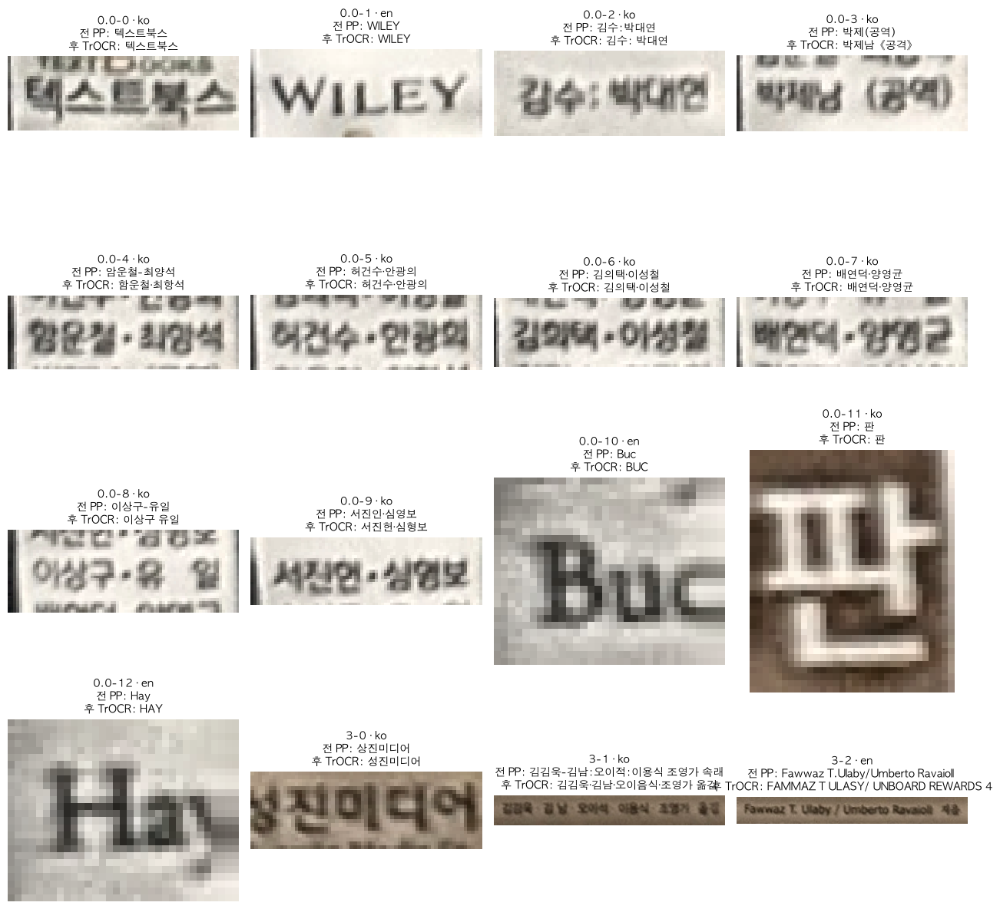

,사진,책,줄,언어,전 · PP-OCR,PP 점수,후 · TrOCR,TrOCR 신뢰도
0,IMG_1530.jpg,0.0,0,ko,텍스트북스,1.00,텍스트북스,1.00
1,IMG_1530.jpg,0.0,1,en,WILEY,1.00,WILEY,0.99
2,IMG_1530.jpg,0.0,2,ko,김수:박대연,0.83,김수: 박대연,0.79
3,IMG_1530.jpg,0.0,3,ko,박제(공역),0.90,박제남《공격》,0.96
4,IMG_1530.jpg,0.0,4,ko,암운철-최양석,0.86,함운철·최항석,0.73
5,IMG_1530.jpg,0.0,5,ko,허건수·안광의,0.95,허건수·안광의,0.82
6,IMG_1530.jpg,0.0,6,ko,김의택·이성철,0.88,김의택·이성철,0.92
7,IMG_1530.jpg,0.0,7,ko,배연덕·양영균,0.86,배연덕·양영균,0.90
8,IMG_1530.jpg,0.0,8,ko,이상구-유일,0.84,이상구 유일,0.59
9,IMG_1530.jpg,0.0,9,ko,서진인·심영보,0.91,서진헌·심형보,0.91


[IMG_1587.jpg]


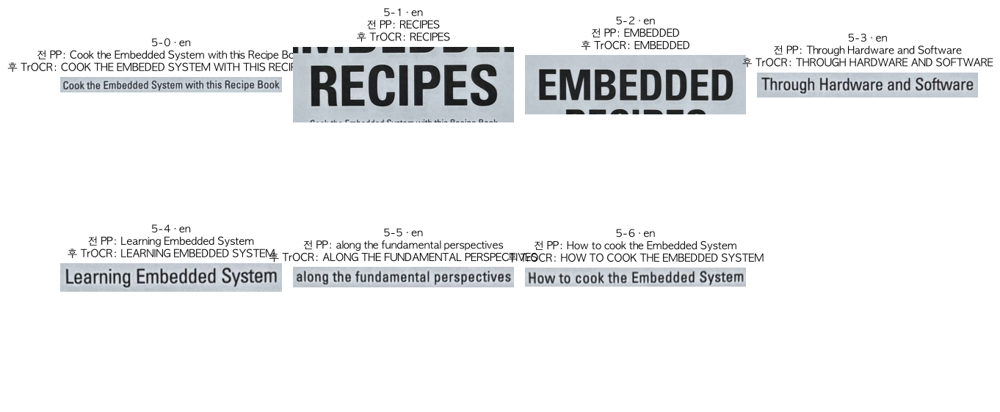

,사진,책,줄,언어,전 · PP-OCR,PP 점수,후 · TrOCR,TrOCR 신뢰도
0,IMG_1587.jpg,5,0,en,Cook the Embedded System with this Recipe Book,0.99,COOK THE EMBEDED SYSTEM WITH THIS RECIPE BOOK,0.93
1,IMG_1587.jpg,5,1,en,RECIPES,1.00,RECIPES,0.86
2,IMG_1587.jpg,5,2,en,EMBEDDED,1.00,EMBEDDED,0.82
3,IMG_1587.jpg,5,3,en,Through Hardware and Software,0.99,THROUGH HARDWARE AND SOFTWARE,0.94
4,IMG_1587.jpg,5,4,en,Learning Embedded System,0.99,LEARNING EMBEDDED SYSTEM,0.87
5,IMG_1587.jpg,5,5,en,along the fundamental perspectives,1.00,ALONG THE FUNDAMENTAL PERSPECTIVES,0.93
6,IMG_1587.jpg,5,6,en,How to cook the Embedded System,0.97,HOW TO COOK THE EMBEDDED SYSTEM,0.91


[IMG_1588.jpg]


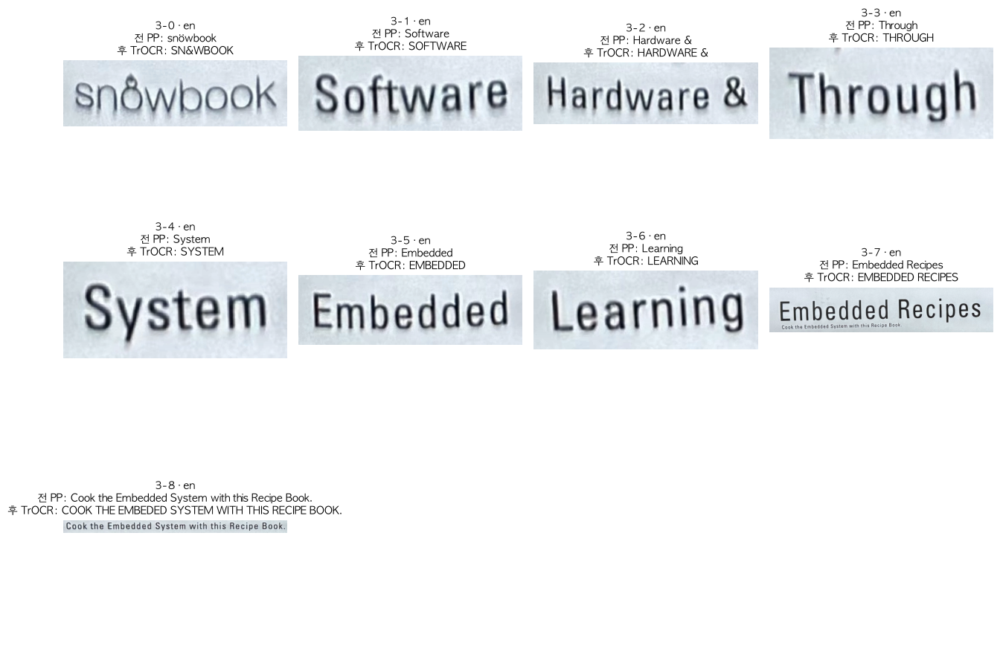

,사진,책,줄,언어,전 · PP-OCR,PP 점수,후 · TrOCR,TrOCR 신뢰도
0,IMG_1588.jpg,3,0,en,snöwbook,0.92,SN&WBOOK,0.78
1,IMG_1588.jpg,3,1,en,Software,1.00,SOFTWARE,0.84
2,IMG_1588.jpg,3,2,en,Hardware &,0.95,HARDWARE &,1.00
3,IMG_1588.jpg,3,3,en,Through,1.00,THROUGH,1.00
4,IMG_1588.jpg,3,4,en,System,1.00,SYSTEM,1.00
5,IMG_1588.jpg,3,5,en,Embedded,1.00,EMBEDDED,0.89
6,IMG_1588.jpg,3,6,en,Learning,1.00,LEARNING,0.99
7,IMG_1588.jpg,3,7,en,Embedded Recipes,1.00,EMBEDDED RECIPES,0.77
8,IMG_1588.jpg,3,8,en,Cook the Embedded System with this Recipe Book.,0.99,COOK THE EMBEDED SYSTEM WITH THIS RECIPE BOOK.,0.92


[IMG_1591.jpg]


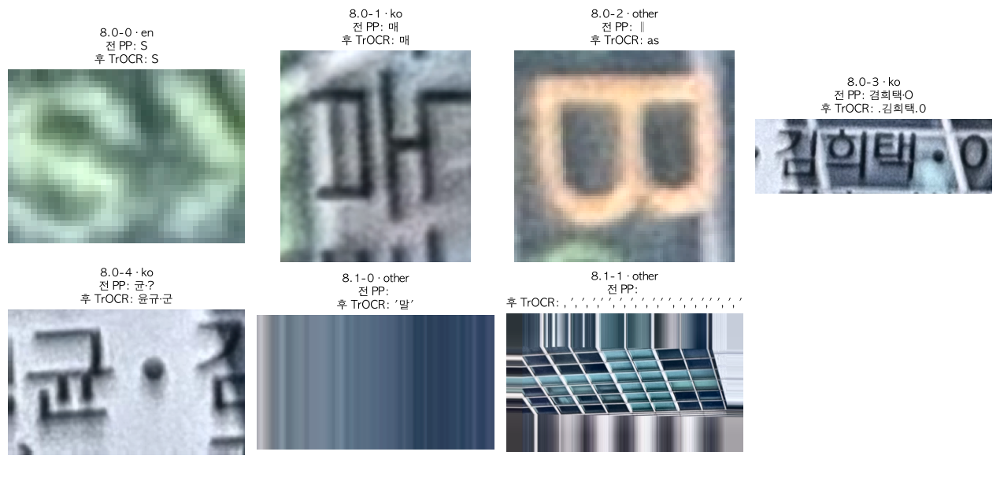

,사진,책,줄,언어,전 · PP-OCR,PP 점수,후 · TrOCR,TrOCR 신뢰도
0,IMG_1591.jpg,8.0,0,en,S,0.59,S,0.93
1,IMG_1591.jpg,8.0,1,ko,매,0.99,매,0.96
2,IMG_1591.jpg,8.0,2,other,‖,0.41,as,0.14
3,IMG_1591.jpg,8.0,3,ko,겸희택·O,0.75,.김희택.0,0.66
4,IMG_1591.jpg,8.0,4,ko,균·?,0.79,윤규·군,0.40
5,IMG_1591.jpg,8.1,0,other,,0.00,'말',0.40
6,IMG_1591.jpg,8.1,1,other,,0.00,", ', ', ',' ', ', ', ', ',' ', ', ', ',' ', ', '",0.61


[IMG_1593.jpg]


Glyph 12539 (\N{KATAKANA MIDDLE DOT}) missing from font(s) AppleGothic.
Glyph 12539 (\N{KATAKANA MIDDLE DOT}) missing from font(s) AppleGothic.


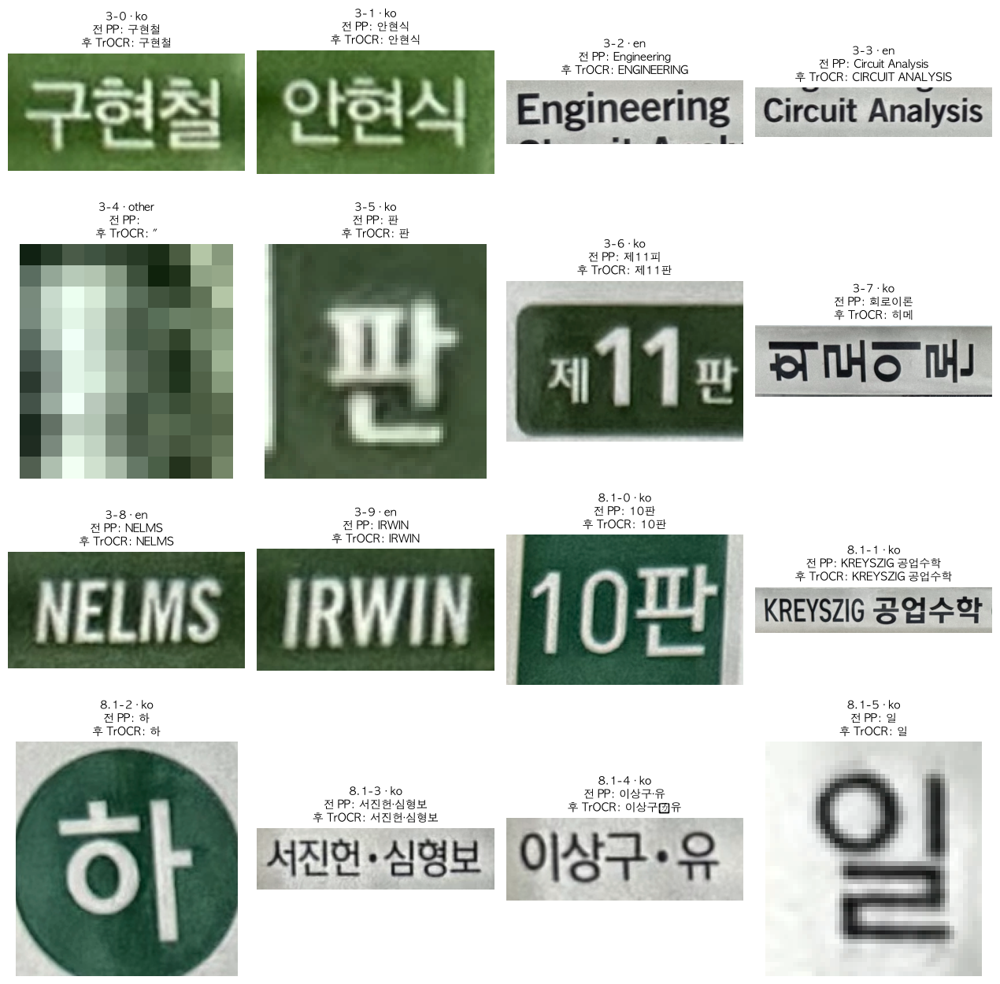

,사진,책,줄,언어,전 · PP-OCR,PP 점수,후 · TrOCR,TrOCR 신뢰도
0,IMG_1593.jpg,3,0,ko,구현철,1.00,구현철,0.99
1,IMG_1593.jpg,3,1,ko,안현식,1.00,안현식,1.00
2,IMG_1593.jpg,3,2,en,Engineering,1.00,ENGINEERING,0.99
3,IMG_1593.jpg,3,3,en,Circuit Analysis,1.00,CIRCUIT ANALYSIS,0.96
4,IMG_1593.jpg,3,4,other,,0.00,"""",0.95
5,IMG_1593.jpg,3,5,ko,판,0.98,판,0.97
6,IMG_1593.jpg,3,6,ko,제11피,0.86,제11판,0.97
7,IMG_1593.jpg,3,7,ko,회로이론,1.00,히메,0.51
8,IMG_1593.jpg,3,8,en,NELMS,1.00,NELMS,0.89
9,IMG_1593.jpg,3,9,en,IRWIN,1.00,IRWIN,0.93


[IMG_1605.jpg]


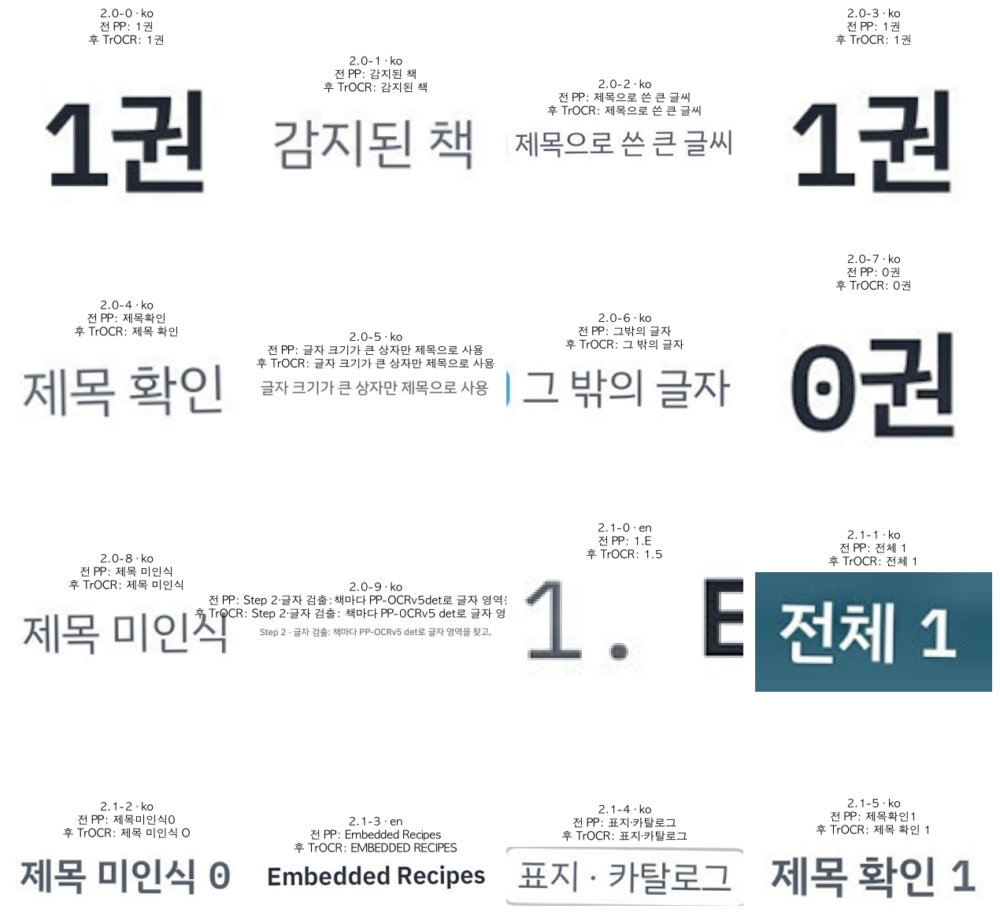

,사진,책,줄,언어,전 · PP-OCR,PP 점수,후 · TrOCR,TrOCR 신뢰도
0,IMG_1605.jpg,2.0,0,ko,1권,1.00,1권,1.00
1,IMG_1605.jpg,2.0,1,ko,감지된 책,0.91,감지된 책,1.00
2,IMG_1605.jpg,2.0,2,ko,제목으로 쓴 큰 글씨,0.96,제목으로 쓴 큰 글씨,1.00
3,IMG_1605.jpg,2.0,3,ko,1권,1.00,1권,1.00
4,IMG_1605.jpg,2.0,4,ko,제목확인,1.00,제목 확인,1.00
5,IMG_1605.jpg,2.0,5,ko,글자 크기가 큰 상자만 제목으로 사용,0.99,글자 크기가 큰 상자만 제목으로 사용,1.00
6,IMG_1605.jpg,2.0,6,ko,그밖의 글자,0.94,그 밖의 글자,1.00
7,IMG_1605.jpg,2.0,7,ko,0권,0.99,0권,1.00
8,IMG_1605.jpg,2.0,8,ko,제목 미인식,0.92,제목 미인식,1.00
9,IMG_1605.jpg,2.0,9,ko,"Step 2·글자 검출:책마다 PP-OCRv5det로 글자 영역을 찾고,",0.97,"Step 2·글자 검출: 책마다 PP-0CRv5 det로 글자 영역을 찾고,",0.89


In [77]:
# Cell 8-2 · ✅ Block 8 확인: 글자 줄 이미지 → 인식 글자
#   줄마다 [입력: 정렬된 글자 줄 이미지] 의 제목에 [Block 6 미리보기(PP-OCR) → Block 8 결과(TrOCR)] 를 같이 적어 비교
#   표: 두 인식기의 결과·신뢰도를 나란히
REC_SHOW = 16

for name, r in PIPE.items():
    items, table = [], []
    for c in r["chunks"]:
        for i, l in enumerate(c["lines"]):
            table.append({"사진": name, "책": c["id"], "줄": i, "언어": l.get("lang"),
                          "전 · PP-OCR": l.get("pp_text", ""), "PP 점수": round(l.get("pp_score", 0), 2),
                          "후 · TrOCR": l.get("text", ""), "TrOCR 신뢰도": round(l.get("conf", 0), 2)})
            if len(items) < REC_SHOW:
                items.append((f"{c['id']}-{i} · {l.get('lang')}\n전 PP: {l.get('pp_text', '')}\n후 TrOCR: {l.get('text', '')}",
                              to_rgb(l["roi"])))
    if items:
        print(f"[{name}]")
        show_grid(items, cols=4, size=3.2)
        display(pd.DataFrame(table))

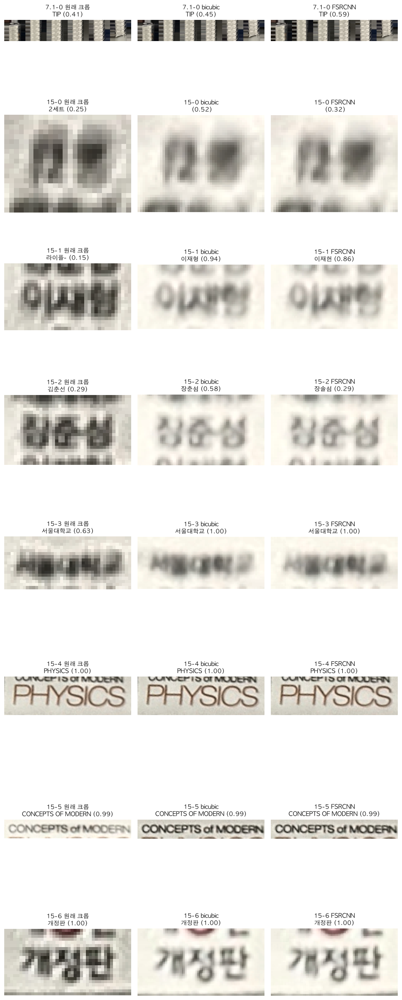

,사진,책,줄,언어,원래 크롭 글자,bicubic 글자,FSRCNN 글자,원래 크롭 신뢰도,bicubic 신뢰도,FSRCNN 신뢰도,세 결과 일치
0,IMG_1530.jpg,7.1,0,en,TIP,TIP,TIP,0.414,0.448,0.586,True
1,IMG_1530.jpg,15,0,ko,2세트,,,0.245,0.523,0.322,False
2,IMG_1530.jpg,15,1,ko,라이플-,이재형,이재헌,0.147,0.943,0.860,False
3,IMG_1530.jpg,15,2,ko,김춘선,장춘섬,장솔섬,0.290,0.583,0.293,False
4,IMG_1530.jpg,15,3,ko,서울대학교,서울대학교,서울대학교,0.629,1.000,0.999,True
5,IMG_1530.jpg,15,4,en,PHYSICS,PHYSICS,PHYSICS,0.998,0.998,0.998,True
6,IMG_1530.jpg,15,5,en,CONCEPTS OF MODERN,CONCEPTS OF MODERN,CONCEPTS OF MODERN,0.993,0.993,0.993,True
7,IMG_1530.jpg,15,6,ko,개정판,개정판,개정판,1.000,1.000,1.000,True
8,IMG_1530.jpg,15,7,ko,제6판,제6판,제6막,0.907,0.923,0.849,False
9,IMG_1530.jpg,15,8,ko,|柿 매 리 ···],|柿 매 리 ···,|柿 매 ᄠᆼ ᄀᆞᆯ,0.229,0.246,0.456,False


,원래 크롭,bicubic,FSRCNN
평균 신뢰도,0.753,0.783,0.785
가장 높은 줄 수,25.000,14.000,17.000


In [78]:
# Cell 8-3 · ✅ Block 4 효과 검증: 같은 글자 줄을 [원래 크롭 | bicubic | FSRCNN] 으로 각각 인식해 비교
#   - 업스케일한 책(x2 이상)의 글자 줄만. 정답 제목이 없으므로 신뢰도와 세 결과의 일치 여부로 본다
#   - FSRCNN의 평균 신뢰도가 bicubic·원래 크롭보다 높으면 Block 4를 유지할 근거
AB_SHOW = 8

ab_rows, ab_items = [], []
for name, r in PIPE.items():
    for c in r["chunks"]:
        s = c["sr_scale"]
        if s == 1:
            continue
        H, W = c["crop_sr"].shape[:2]
        bic = cv2.resize(c["crop"], (W, H), interpolation=cv2.INTER_CUBIC)
        for i, l in enumerate(c["lines"]):
            variants = {
                "원래 크롭": align_roi(c["crop"], {**l, "quad": l["quad"] / s}),
                "bicubic": align_roi(bic, l),
                "FSRCNN": l["roi"],
            }
            res = {}
            for k, im in variants.items():
                tmp = {k2: v for k2, v in l.items() if k2 not in ("text", "conf")}  # 이전 결과가 남지 않게
                read_lines([(tmp, im)])
                res[k] = (tmp.get("text", ""), tmp.get("conf", 0.0))
            ab_rows.append({"사진": name, "책": c["id"], "줄": i, "언어": l.get("lang"),
                            **{f"{k} 글자": v[0] for k, v in res.items()},
                            **{f"{k} 신뢰도": round(v[1], 3) for k, v in res.items()},
                            "세 결과 일치": len({v[0] for v in res.values()}) == 1})
            if len(ab_items) < AB_SHOW * 3:
                for k, im in variants.items():
                    ab_items.append((f"{c['id']}-{i} {k}\n{res[k][0]} ({res[k][1]:.2f})", to_rgb(im)))

if ab_rows:
    ab = pd.DataFrame(ab_rows)
    show_grid(ab_items, cols=3, size=3.2)
    display(ab)
    display(pd.DataFrame({k: {"평균 신뢰도": round(ab[f"{k} 신뢰도"].mean(), 3),
                              "가장 높은 줄 수": int((ab[[f"{x} 신뢰도" for x in ("원래 크롭", "bicubic", "FSRCNN")]]
                                                   .idxmax(axis=1) == f"{k} 신뢰도").sum())}
                          for k in ("원래 크롭", "bicubic", "FSRCNN")}))
else:
    print("업스케일한 책이 없어 비교할 줄이 없습니다")

<div style="border-left: 10px solid #4fa3d1; padding: 10px 18px; margin: 8px 0 4px; background: rgba(127,127,127,0.08); border-radius: 4px;">
<h1 style="font-size: 2.3em; margin: 0;">Block 9 · Text Normalization (비신경망 교정) + 최종 결과</h1>
<h3 style="font-size: 1.35em; margin: 6px 0 0; font-weight: 500;">실제 단어·제목 후보 중에서만 골라 OCR 오류를 바로잡고 최종 결과를 낸다 &nbsp;<small>[Sub Model 2 · Subtitle Detection]</small></h3>
</div>

<div style="font-size: 1.15em; line-height: 1.7;">

책마다 글자 줄에서 **제목을 조립**하고, OCR 오류를 **실제로 있는 단어·제목 후보 중에서만** 골라 바로잡는다 (없는 말을 지어내지 않음).

> **mBART-50을 뺀 이유** (1차 테스트): 고친 제목 0건, 지어낸 문장 6건(`회동론`→`홈 > 게시판 > 자유게시판` 등, 안전장치가 차단).
> 사전학습 언어모델이라 OCR 오류 교정이 아니라 '그럴듯한 문장 생성'으로 동작했고, 2.4GB·LLM 제약 위험도 있음.

| 단계 | 셀 | 방법 | 모델 |
|---|---|---|---|
| 제목 조립 · 규칙 정리 | 9-1 | 저자·출판사·판수 줄, 크롭 경계에 잘린 줄 제외 → 큰 글씨 줄만 위→아래로 | 없음 |
| ② 단어 교정 + 어순 | 9-2 | 단어마다 사전에서 자모 편집거리 ≤ 2인 후보 → 글자 5-gram 언어모델(Kneser-Ney) 점수로 최선 조합 선택, 여러 줄은 가장 자연스러운 순서 선택 | 통계표 (직접 구현) |
| ① 도서 목록 매칭 | 9-3 | 자모 단위 편집거리 + bigram 역색인, 1·2위 점수 차·권차·포함 관계 검증 후 확정 (`src/matcher.py` 재사용) | 없음 |

- 사전·언어모델·목록은 `catalog/catalog.json`(121권) + **Kaggle Book Covers 영어 제목 약 3.2만 개**(CC0, 메타데이터만 사용)에서 만든다
  → 국립중앙도서관 API 키가 나오면 한국어 도서로 확장. Kaggle 저자 이름은 '제목 아닌 줄' 판정에도 씀
- ⚠️ 이 목록에는 테스트 사진 속 책 제목이 들어 있어(이전 프로젝트에서 데모용으로 추가) **결과가 실제보다 낙관적**이다. 실서비스는 밀리의서재 도서 DB 전체가 목록이 된다
- 최종 제목 우선순위: ① 목록 확정 > ② 교정 결과 > 규칙 정리 원문

</div>


In [94]:
# Cell 9-1 · [제목 조립 · 규칙 정리] 글자 줄 → 제목 후보 줄 고르기
#   - 제외: 신뢰도 낮은 줄, 숫자·기호 줄(other), 크롭 좌우 경계에 걸려 잘린 줄,
#           저자·출판사·시리즈(catalog/non_titles.txt + 이름 패턴), 판수·개정판
#   - 남은 줄 중 글자 높이가 가장 큰 줄의 size_ratio 이상인 줄만, 위→아래 순서로
#   - 출력: chunk["title_lines"] (고른 줄 글자 목록), chunk["title_raw"] (이어 붙인 제목)
import sys
import unicodedata

from rapidfuzz import fuzz, process

sys.path.insert(0, str(ROOT.parent / "src"))
from matcher import TitleMatcher, is_garbage, normalize, to_jamo  # 이전 프로젝트에서 검증한 자모 매칭

CATALOG_DIR = ROOT.parent / "catalog"
TITLE_RULES = {"min_conf": 0.30, "size_ratio": 0.60, "max_lines": 4, "edge": 0.02, "non_title_sim": 85,
               "cover_ratio": 0.75, "cover_max_lines": 3,   # 표지(크롭 세로/가로 < 2): 비슷한 크기의 광고 문구가 많아 더 엄격하게
               "num_ratio": 0.75}                           # 숫자만 있는 줄(2027 등)도 이만큼 크면 제목에 포함

NON_TITLES = [l.strip() for l in (CATALOG_DIR / "non_titles.txt").read_text().splitlines()
              if l.strip() and not l.startswith("#")]
NON_TITLE_KEYS = [normalize(t) for t in NON_TITLES]

# Kaggle Book Covers(CC0) 메타데이터: 영어 제목 → ②·① 사전·목록 확장 (Cell 9-2), 저자 → 제목 아님 판정
#   data/archive.zip(또는 liber_deprehensus/archive.zip)에서 main_dataset.csv만 꺼내 씀. 표지 이미지는 쓰지 않음
KAGGLE_CSV = DATA / "kaggle_covers" / "main_dataset.csv"
if not KAGGLE_CSV.exists():
    zp = next((p for p in (DATA / "archive.zip", ROOT / "archive.zip") if p.exists()), None)
    if zp:
        import zipfile
        KAGGLE_CSV.parent.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(zp) as z:
            KAGGLE_CSV.write_bytes(z.read("main_dataset.csv"))
if KAGGLE_CSV.exists():
    kg = pd.read_csv(KAGGLE_CSV, usecols=["name", "author"])
    EXTRA_TITLES = list(dict.fromkeys(t.strip() for t in kg["name"].dropna() if 2 <= len(t.strip()) <= 80))
    AUTHOR_KEYS = sorted({normalize(a) for a in kg["author"].dropna() if len(normalize(a)) >= 6})
    print(f"Kaggle 메타데이터: 영어 제목 {len(EXTRA_TITLES):,} · 저자 {len(AUTHOR_KEYS):,}")
else:
    EXTRA_TITLES, AUTHOR_KEYS = [], []
    print("Kaggle 메타데이터 없음 (data/archive.zip을 두면 사용)")
AUTHOR_SET = set(AUTHOR_KEYS)
AUTHOR = re.compile(r"(지음|지은이|옮김|공역|편역|편저|감수|역|저|著)\s*$"          # …지음, …옮김
                    r"|^[가-힣]{2,4}\s*[·•+∙,]\s*[가-힣]{2,4}"                     # 홍길동·김철수
                    r"|[《〈(\[]\s*(공?역|공?저|편|감수|옮김)\s*[》〉)\]]"           # 박제남〈공역〉
                    r"|^.{0,3}수\s*:"                                                 # 감수: 홍길동
                    r"|^([가-힣]{3}\s+){2,}[가-힣]{3}$")                               # 안현식 구성철 박종후 (구분 기호가 빠진 저자 목록)
EDITION = re.compile(r"^(제?\s*\d+\s*판|개정\s*\d*\s*판|전면\s*개정판|\d+(st|nd|rd|th)?\s*edition|edition)$", re.I)


def clean(text):
    text = unicodedata.normalize("NFC", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip(" .,:;·-_|/\\'\"")


def line_height(l):
    (_, _), (w, h), _ = cv2.minAreaRect(l["quad"])
    return min(w, h)


def touches_side(l, width):
    """책등을 가로지르는 가로 줄이 좌우 경계에 닿음 = 잘린 줄. 책등을 따라 세로로 쓴 큰 제목은 폭을 꽉 채워도 해당 안 됨"""
    q, m = l["quad"], TITLE_RULES["edge"] * width
    across = np.ptp(q[:, 0]) >= np.ptp(q[:, 1])
    return across and (q[:, 0].min() <= m or q[:, 0].max() >= width - 1 - m)


def non_title_reason(text):
    key = normalize(text)
    if not key or is_garbage(text):
        return "잡음"
    if EDITION.match(text.strip()):
        return "판수"
    if AUTHOR.search(text):
        return "저자"
    if key in AUTHOR_SET or (len(key) >= 6 and AUTHOR_KEYS and process.extractOne(key, AUTHOR_KEYS, scorer=fuzz.ratio, score_cutoff=92)):
        return "저자"   # Kaggle 저자 이름과 (거의) 같음
    if any(key == k or (len(key) >= 3 and fuzz.ratio(key, k) >= TITLE_RULES["non_title_sim"]) for k in NON_TITLE_KEYS):
        return "출판사·시리즈"
    return ""


def assemble_title(c):
    H, W = c["crop_sr"].shape[:2]
    cover = H < 2 * W
    ratio = TITLE_RULES["cover_ratio" if cover else "size_ratio"]
    max_lines = TITLE_RULES["cover_max_lines" if cover else "max_lines"]
    cands, nums = [], []
    for l in c["lines"]:
        text = clean(l.get("text", ""))
        if l.get("conf", 0) >= TITLE_RULES["min_conf"] and re.fullmatch(r"\d{2,4}", text):
            nums.append((l, text))   # 연도·권 번호: 크면 아래에서 제목에 포함
        why = ("신뢰도" if l.get("conf", 0) < TITLE_RULES["min_conf"] else
               "숫자·기호" if l.get("lang") == "other" else
               "경계 잘림" if touches_side(l, W) else non_title_reason(text))
        l["title_skip"] = why
        if not why:
            cands.append((l, text))
    if not cands:
        return []
    top = max(line_height(l) for l, _ in cands)
    sel = sorted([(l, t) for l, t in cands if line_height(l) >= ratio * top], key=lambda x: -line_height(x[0]))[:max_lines]
    sel += [(l, t) for l, t in nums if line_height(l) >= TITLE_RULES["num_ratio"] * top]
    for l, _ in cands:
        if all(l is not s for s, _ in sel):
            l["title_skip"] = "작은 글씨"
    sel.sort(key=lambda x: (x[0]["quad"][:, 1].mean(), x[0]["quad"][:, 0].mean()))
    return [t for _, t in sel]


for name, r in PIPE.items():
    for c in r["chunks"]:
        c["title_lines"] = assemble_title(c)
        c["title_raw"] = " ".join(c["title_lines"])
    skips = pd.Series([l.get("title_skip") or "제목 줄" for c in r["chunks"] for l in c["lines"]]).value_counts()
    print(f"{name}: " + ", ".join(f"{k} {v}" for k, v in skips.items()))

IMG_1530.jpg: 작은 글씨 29, 제목 줄 27, 저자 17, 출판사·시리즈 10, 잡음 9, 경계 잘림 8, 숫자·기호 4, 판수 3, 신뢰도 3
IMG_1587.jpg: 작은 글씨 5, 제목 줄 2
IMG_1588.jpg: 작은 글씨 8, 제목 줄 1
IMG_1591.jpg: 잡음 2, 제목 줄 2, 숫자·기호 2, 신뢰도 1
IMG_1593.jpg: 작은 글씨 20, 잡음 7, 숫자·기호 6, 경계 잘림 6, 제목 줄 5, 저자 5, 출판사·시리즈 4, 판수 2, 신뢰도 2
IMG_1605.jpg: 제목 줄 12, 작은 글씨 3, 저자 1


In [95]:
# Cell 9-2 · [② 단어 교정 + 어순] 사전 후보(자모 편집거리) × 글자 5-gram 언어모델
#   - 사전·언어모델: 도서 목록 제목에서 만든다 (신경망 아님, 통계표)
#   - 단어마다 [원래 단어 + 사전에서 자모 편집거리 ≤ 허용치인 후보] → 빔 서치로 문장 점수가 가장 높은 조합
#     허용치 = min(max_edit, 자모 길이 × edit_ratio). 숫자·기호만 있는 단어, 자모 min_jamo개 미만인 짧은 단어는 고치지 않음
#     (1차 테스트에서 `4`→`2`, `또`→`총`, `히메`→`힘`처럼 짧은 단어가 사전 단어로 바뀌는 과잉 교정이 있었음)
#     문장 점수 = 언어모델 로그확률 − err_weight × 편집거리 합   (잡음 채널: P(제목) × P(OCR | 제목))
#   - 줄이 2~4개면 모든 순서를 이어 보고 글자당 점수가 원래 순서보다 order_margin 이상 높을 때만 바꿈
#   - 출력: chunk["title_corr"]
import itertools
import json
import math
from collections import Counter, defaultdict

from rapidfuzz import process
from rapidfuzz.distance import Levenshtein

CORR_RULES = {"n": 5, "max_edit": 2, "edit_ratio": 0.25, "min_jamo": 5, "err_weight": 4.0,
              "beam": 8, "cands": 5, "order_margin": 0.5}   # 어순은 위→아래가 기본, 확실히 자연스러울 때만 바꿈

# 도서 목록 = 데모 카탈로그(121권) + Kaggle 영어 제목 (실서비스에서는 밀리의서재 도서 DB 전체)
CATALOG = list(dict.fromkeys(json.loads((CATALOG_DIR / "catalog.json").read_text()) + EXTRA_TITLES))


class CharKN:
    """글자 n-gram 언어모델 (보간 Kneser-Ney). 제목 목록에서 글자 배열의 자연스러움을 센다"""

    def __init__(self, texts, n=5, d=0.75):
        self.n, self.d = n, d
        self.cnt = {n: Counter()}
        for t in texts:
            s = "^" * (n - 1) + t + "$"
            for i in range(n - 1, len(s)):
                self.cnt[n][s[i - n + 1:i + 1]] += 1
        for k in range(n - 1, 0, -1):  # 낮은 차수는 '몇 가지 앞 글자 뒤에 나왔나'(continuation count)
            self.cnt[k] = Counter(g[1:] for g in self.cnt[k + 1])
        self.tot, self.typ = {}, {}
        for k, cnt in self.cnt.items():
            tot, typ = defaultdict(int), defaultdict(int)
            for g, v in cnt.items():
                tot[g[:-1]] += v
                typ[g[:-1]] += 1
            self.tot[k], self.typ[k] = tot, typ
        self.V = len(self.cnt[1]) + 1

    def prob(self, h, w):
        p = 1.0 / self.V
        for k in range(1, self.n + 1):
            ctx = h[len(h) - (k - 1):] if k > 1 else ""
            c_h = self.tot[k].get(ctx, 0)
            if c_h:
                p = max(self.cnt[k].get(ctx + w, 0) - self.d, 0) / c_h + self.d * self.typ[k][ctx] / c_h * p
        return p

    def logprob(self, text):
        s = "^" * (self.n - 1) + text + "$"
        return sum(math.log(self.prob(s[i - self.n + 1:i], s[i])) for i in range(self.n - 1, len(s)))

    def per_char(self, text):
        return self.logprob(text) / (len(text) + 1)


def lm_key(text):
    return re.sub(r"\s+", " ", text.lower()).strip()


lm = CharKN([lm_key(t) for t in CATALOG], n=CORR_RULES["n"])
VOCAB = {}  # 소문자 단어 → 표시용 단어
for t in CATALOG:
    for w in t.split():
        VOCAB.setdefault(w.lower(), w)
VOCAB_KEYS = list(VOCAB)
VOCAB_JAMO = [to_jamo(w) for w in VOCAB_KEYS]
print(f"사전 {len(VOCAB)}단어 · 언어모델 {CORR_RULES['n']}-gram {len(lm.cnt[CORR_RULES['n']]):,}종 (제목 {len(CATALOG)}개)")


def word_options(word):
    key = word.lower()
    if key in VOCAB:
        return [(VOCAB[key], 0)]
    opts = [(word, 0)]
    jamo = to_jamo(key)
    max_ed = min(CORR_RULES["max_edit"], int(len(jamo) * CORR_RULES["edit_ratio"]))
    if not re.search(r"[A-Za-z가-힣]", word) or len(jamo) < CORR_RULES["min_jamo"] or max_ed == 0:
        return opts
    hits = process.extract(jamo, VOCAB_JAMO, scorer=Levenshtein.distance,
                           limit=CORR_RULES["cands"], score_cutoff=max_ed)
    opts += [(VOCAB[VOCAB_KEYS[i]], int(d)) for _, d, i in hits if d > 0]
    return opts


def correct_line(text):
    beams = [("", 0)]
    for word in text.split():
        nxt = [((b + " " + w).strip(), e + d) for b, e in beams for w, d in word_options(word)]
        nxt.sort(key=lambda x: -(lm.logprob(lm_key(x[0])) - CORR_RULES["err_weight"] * x[1]))
        beams = nxt[:CORR_RULES["beam"]]
    return beams[0][0] if beams else text


def best_order(lines):
    if not 2 <= len(lines) <= 4:
        return lines
    base = lm.per_char(lm_key(" ".join(lines)))
    best = max(itertools.permutations(lines), key=lambda p: lm.per_char(lm_key(" ".join(p))))
    return list(best) if lm.per_char(lm_key(" ".join(best))) - base >= CORR_RULES["order_margin"] else lines


for name, r in PIPE.items():
    for c in r["chunks"]:
        lines = [correct_line(t) for t in c["title_lines"]]
        c["title_corr"] = " ".join(best_order(lines))
    changed = sum(c["title_corr"] != c["title_raw"] for c in r["chunks"])
    print(f"{name}: {len(r['chunks'])}권 중 교정으로 바뀐 제목 {changed}권")

사전 238단어 · 언어모델 5-gram 1,040종 (제목 121개)
IMG_1530.jpg: 14권 중 교정으로 바뀐 제목 4권
IMG_1587.jpg: 2권 중 교정으로 바뀐 제목 1권
IMG_1588.jpg: 1권 중 교정으로 바뀐 제목 1권
IMG_1591.jpg: 2권 중 교정으로 바뀐 제목 0권
IMG_1593.jpg: 5권 중 교정으로 바뀐 제목 2권
IMG_1605.jpg: 2권 중 교정으로 바뀐 제목 2권


In [96]:
# Cell 9-3 · [① 도서 목록 매칭] 교정 제목·원문 → 목록에서 확정
#   - src/matcher.py의 TitleMatcher: 자모 편집거리 + bigram 역색인, 검증(1·2위 점수 차, 권차 상/하, 포함 관계, 짧은 제목)
#   - 질의: [② 교정 제목, 규칙 정리 원문, 고른 줄 각각] 중 검증을 통과한 최고 점수 (context = 그 책의 모든 줄 → 권차 확인용)
#   - 최종 제목: ① 확정 > ② 교정 > 원문.  출력: chunk["match"], chunk["title"], chunk["title_src"]
MATCH_MIN = 75
LINE_MATCH_MIN = 88   # 제목 줄이 아닌 줄로 확정할 때는 더 높은 점수

matcher = TitleMatcher([{"title": t, "isbn": ""} for t in CATALOG])


def match_title(c):
    context = " ".join(l.get("text", "") for l in c["lines"])
    best = None
    for q in dict.fromkeys([c["title_corr"], c["title_raw"], *c["title_lines"]]):
        if not q:
            continue
        res = matcher.match(q, context=context)
        if res and res[0]["verified"] and res[0]["score"] >= MATCH_MIN and (best is None or res[0]["score"] > best["score"]):
            best = {**res[0], "query": q}
    # 제목 줄로 뽑히지 않은 줄도: 표지의 카탈로그 제목이 가장 큰 글씨가 아닌 경우 (예: Atomic Habits → 아주 작은 습관의 힘)
    for l in c["lines"]:
        t = l.get("text", "")
        if l.get("title_skip") != "작은 글씨" or len(normalize(t)) < 3:
            continue
        res = matcher.match(t, context=context)
        if res and res[0]["verified"] and res[0]["score"] >= LINE_MATCH_MIN and (best is None or res[0]["score"] > best["score"]):
            best = {**res[0], "query": t}
    return best


for name, r in PIPE.items():
    for c in r["chunks"]:
        c["match"] = match_title(c)
        if c["match"]:
            c["title"], c["title_src"] = c["match"]["title"], "① 목록"
        elif c["title_corr"]:
            c["title"], c["title_src"] = c["title_corr"], "② 교정" if c["title_corr"] != c["title_raw"] else "원문"
        else:
            c["title"], c["title_src"] = "", "-"
    src = pd.Series([c["title_src"] for c in r["chunks"]]).value_counts()
    print(f"{name}: " + ", ".join(f"{k} {v}권" for k, v in src.items()))

IMG_1530.jpg: 원문 5권, ① 목록 5권, ② 교정 2권, - 2권
IMG_1587.jpg: - 1권, ① 목록 1권
IMG_1588.jpg: ① 목록 1권
IMG_1591.jpg: 원문 1권, - 1권
IMG_1593.jpg: ② 교정 2권, 원문 2권, ① 목록 1권
IMG_1605.jpg: ② 교정 1권, ① 목록 1권


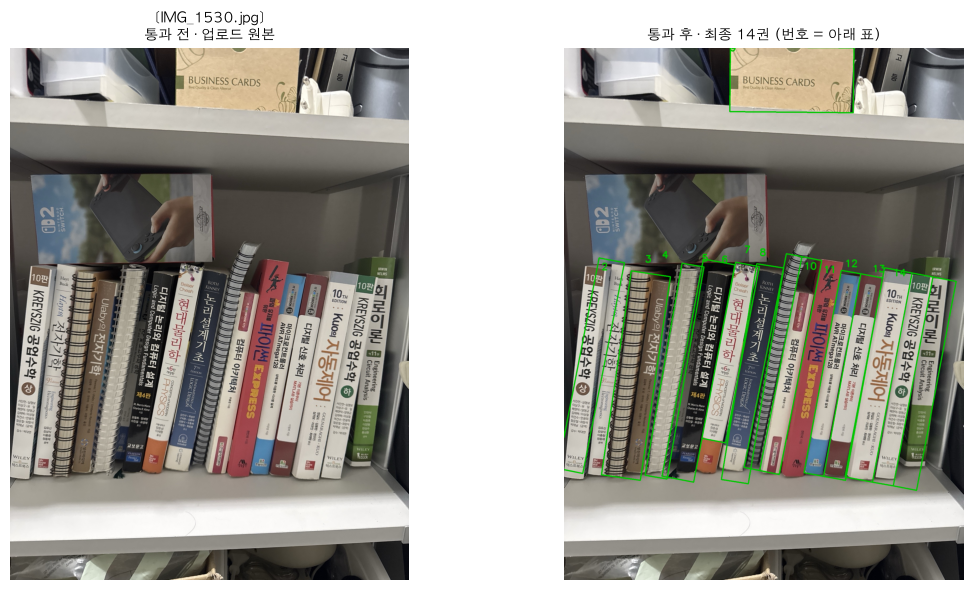

[IMG_1530.jpg] 권수 14권


,번호,책 id,판정,전 · OCR 원문,② 교정,① 목록 매칭,후 · 최종 제목,출처
0,1,0.0,multiple,이상구 유일 박제남《공격》 김수: 박대연,이상구 유일 박제남《공격》 김수: 박대연,,이상구 유일 박제남《공격》 김수: 박대연,원문
1,2,3,book?,FAMMAZ T ULASY/ UNBOARD REWARDS 4 성진미디어,FAMMAZ T ULASY/ UNBOARD REWARDS 2 성진미디어,,FAMMAZ T ULASY/ UNBOARD REWARDS 2 성진미디어,② 교정
2,3,7.1,multiple,,,,(제목 인식 못함),-
3,4,10,book,LOGIC AND COMPUTER DESIGN FUNDAMENAS 디지털 논리와 컴...,디지털 논리와 컴퓨터 설계 LOGIC AND COMPUTER DESIGN FUNDA...,디지털 논리와 컴퓨터 설계 (100.0),디지털 논리와 컴퓨터 설계,① 목록
4,5,15,book,제6막 PHYSICS,제6막 PHYSICS,,제6막 PHYSICS,원문
5,6,13.2,multiple,MIL FUNDAMENTAISO LOGIC DESIGN 김형식 : 우홍체,MIL FUNDAMENTAISO LOGIC DESIGN 김형식 2 우홍체,,MIL FUNDAMENTAISO LOGIC DESIGN 김형식 2 우홍체,② 교정
6,7,18.0,multiple,,,,(제목 인식 못함),-
7,8,18.1,multiple,컴퓨터 아키텍처,컴퓨터 아키텍처,컴퓨터 아키텍처 (100.0),컴퓨터 아키텍처,① 목록
8,9,20,book?,BUSINESS CARDS,BUSINESS CARDS,,BUSINESS CARDS,원문
9,10,22.0,multiple,마이크로컨트롤러 AVR ATMEGA128 상태도를 이용한 시스템 설계 이상성 자유,마이크로컨트롤러 AVR ATmega128 상태도를 이용한 시스템 설계 이상성 이유,마이크로컨트롤러 AVR ATmega128 (92.0),마이크로컨트롤러 AVR ATmega128,① 목록


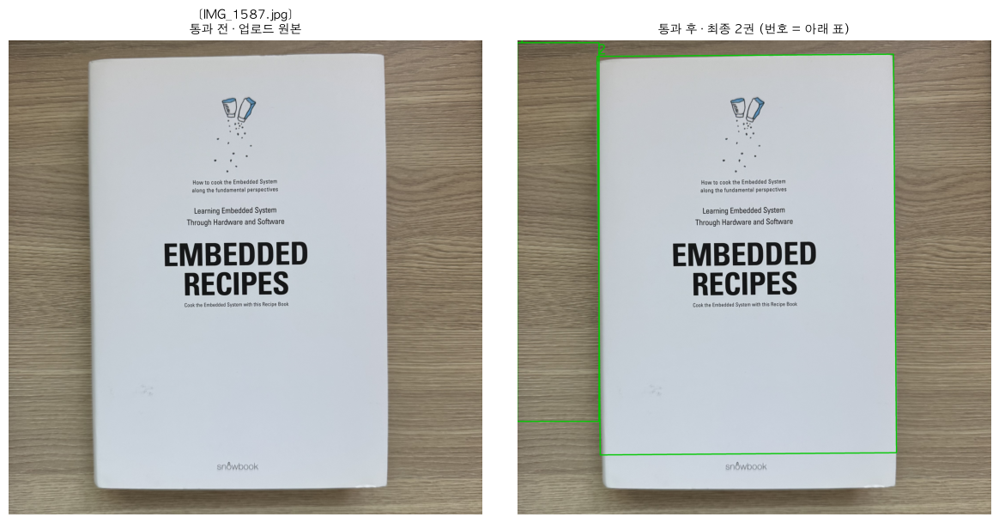

[IMG_1587.jpg] 권수 2권


,번호,책 id,판정,전 · OCR 원문,② 교정,① 목록 매칭,후 · 최종 제목,출처
0,1,0,book,,,,(제목 인식 못함),-
1,2,5,book?,EMBEDDED RECIPES,Embedded Recipes,Embedded Recipes (100.0),Embedded Recipes,① 목록


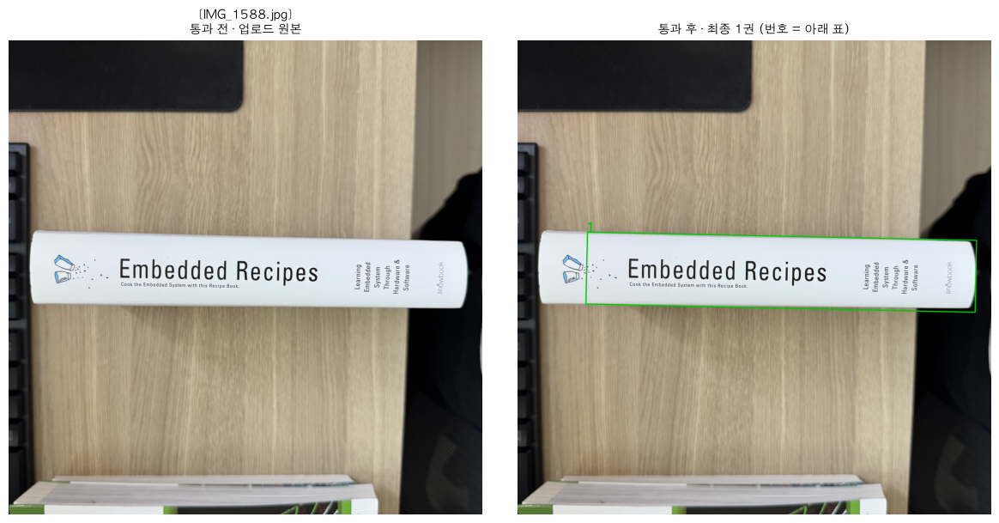

[IMG_1588.jpg] 권수 1권


,번호,책 id,판정,전 · OCR 원문,② 교정,① 목록 매칭,후 · 최종 제목,출처
0,1,3,book?,EMBEDDED RECIPES,Embedded Recipes,Embedded Recipes (100.0),Embedded Recipes,① 목록


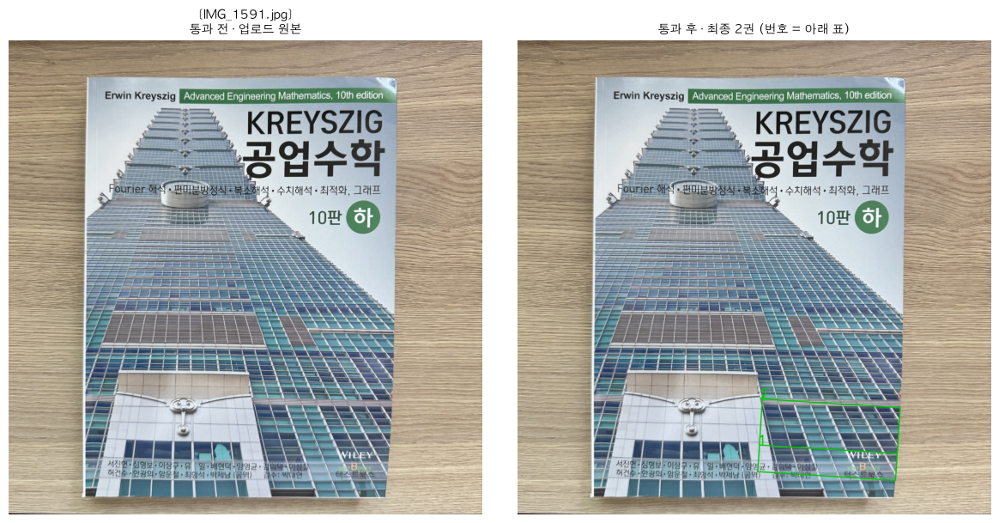

[IMG_1591.jpg] 권수 2권


,번호,책 id,판정,전 · OCR 원문,② 교정,① 목록 매칭,후 · 최종 제목,출처
0,1,8.0,multiple,윤규·군 김희택.0,윤규·군 김희택.0,,윤규·군 김희택.0,원문
1,2,8.1,multiple,,,,(제목 인식 못함),-


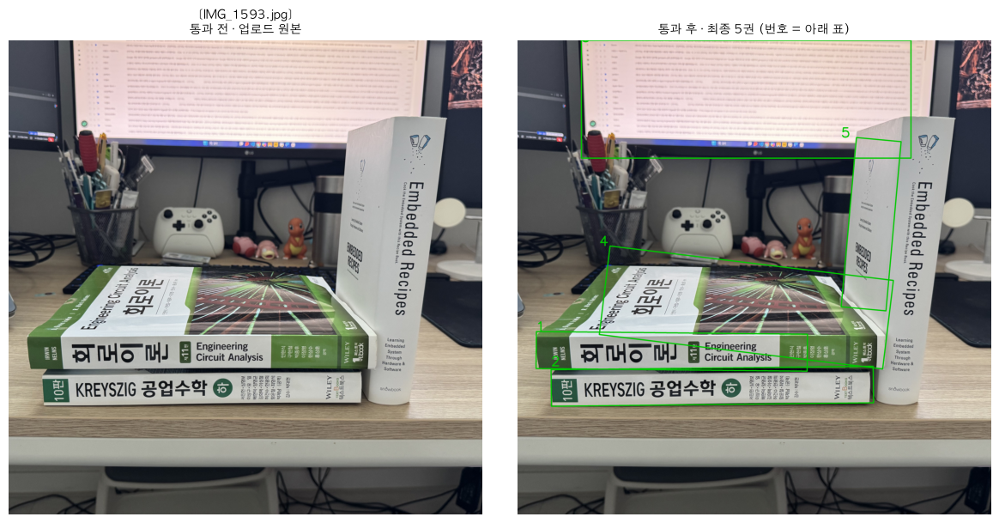

[IMG_1593.jpg] 권수 5권


,번호,책 id,판정,전 · OCR 원문,② 교정,① 목록 매칭,후 · 최종 제목,출처
0,1,3,book,히메,힘,,힘,② 교정
1,2,8.1,multiple,KREYSZIG 공업수학,KREYSZIG 공업수학,공업수학 하 (84.3),공업수학 하,① 목록
2,3,9,book?,또 논란,총 논란,,총 논란,② 교정
3,4,10,book?,UNDERSETTING CUROTH CARDINGS,UNDERSETTING CUROTH CARDINGS,,UNDERSETTING CUROTH CARDINGS,원문
4,5,12,book?,ENGENT,ENGENT,,ENGENT,원문


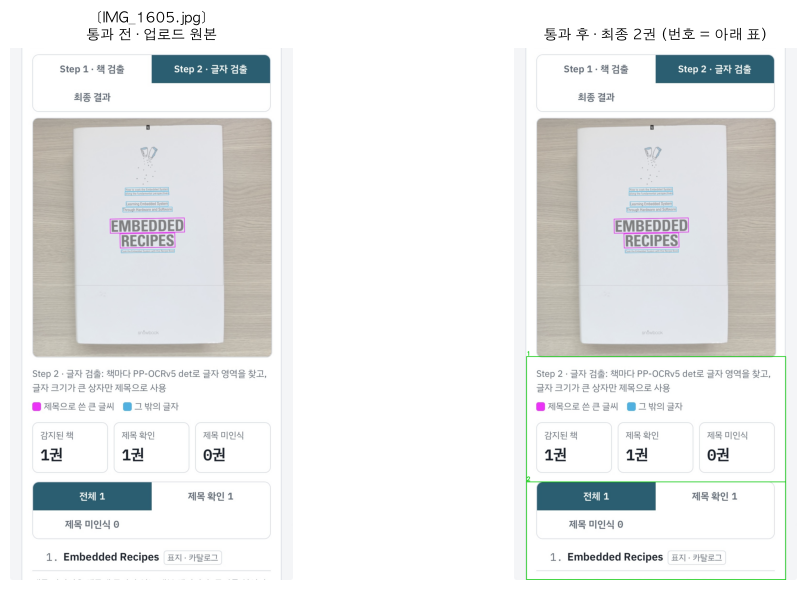

[IMG_1605.jpg] 권수 2권


,번호,책 id,판정,전 · OCR 원문,② 교정,① 목록 매칭,후 · 최종 제목,출처
0,1,2.0,multiple,0권 Step 2·글자 검출: 책마다 PP-0CRv5 det로 글자 영역을 찾고 제...,Deep 2·글자 검출: 책마다 PP-0CRv5 det로 글자 영역을 찾고 균 1권...,,Deep 2·글자 검출: 책마다 PP-0CRv5 det로 글자 영역을 찾고 균 1권...,② 교정
1,2,2.1,multiple,제목 확인 1 EMBEDDED RECIPES 전체 1 제목 미인식 O,Embedded Recipes 제목 확인 2 전체 2 제목 미인식 2,Embedded Recipes (100.0),Embedded Recipes,① 목록


저장 → /Users/minseok/Downloads/shelf_ocr_test/liber_deprehensus/outputs/results.csv, /Users/minseok/Downloads/shelf_ocr_test/liber_deprehensus/outputs/results.json


In [97]:
# Cell 9-4 · ✅ 최종 결과: 권수 + 책별 제목
#   사진마다 [통과 전: 업로드 원본 | 통과 후: 최종 책 상자(번호)]
#   표: 번호 · OCR 원문 → ② 교정 → ① 목록 매칭(점수) → 최종 제목(출처)
#   결과 저장: outputs/results.csv, outputs/results.json
final_rows = []
for name, r in PIPE.items():
    chunks = r["chunks"]
    show_rows([(name, [
        ("통과 전 · 업로드 원본", to_rgb(r["image"])),
        (f"통과 후 · 최종 {len(chunks)}권 (번호 = 아래 표)",
         draw_dets(r["image"], chunks, color=(0, 200, 0), labels=[k + 1 for k in range(len(chunks))])),
    ])], size=6)
    rows = [{"사진": name, "번호": k + 1, "책 id": c["id"], "판정": c["cls"],
             "전 · OCR 원문": c["title_raw"], "② 교정": c["title_corr"],
             "① 목록 매칭": f"{c['match']['title']} ({c['match']['score']})" if c["match"] else "",
             "후 · 최종 제목": c["title"] or "(제목 인식 못함)", "출처": c["title_src"]}
            for k, c in enumerate(chunks)]
    print(f"[{name}] 권수 {len(chunks)}권")
    if rows:   # 책이 0권이면 표가 비어 있어 열이 없음
        display(pd.DataFrame(rows).drop(columns="사진"))
    final_rows += rows

pd.DataFrame(final_rows).to_csv(OUTPUTS / "results.csv", index=False, encoding="utf-8-sig")
(OUTPUTS / "results.json").write_text(json.dumps(
    {n: {"count": BOOK_COUNT[n], "titles": [c["title"] for c in r["chunks"]]} for n, r in PIPE.items()},
    ensure_ascii=False, indent=2))
print(f"저장 → {OUTPUTS / 'results.csv'}, {OUTPUTS / 'results.json'}")